# Texas Salary Prediction Model

### Final Project Structure 
1. Introduction
2. Problem Statement
3. Objectives
4. Dataset Description
5. Import Libraries
6. Load Dataset
7. Initial Data Exploration
8. Data Dictionary
9. Missing Value Analysis
10. Duplicate Analysis
11. Repeated Employee Analysis
12. Data Cleaning
13. Full-Time / Part-Time Analysis
14. Salary Distribution
15. Salary Outlier Analysis
16. Agency Analysis
17. Role / Class Title Analysis
18. Manager vs Employee Analysis
19. Hire Cohort Analysis
20. Salary & Headcount Changes Over Time
21. Tenure Analysis
22. Correlation Analysis
23. Target Leakage Check
24. Feature Engineering
25. Feature Selection
26. Train-Test Split
27. Preprocessing
28. Linear Regression
29. Decision Tree
30. Random Forest
31. Gradient Boosting
32. Model Comparison
33. Final Model Selection
34. Actual vs Predicted Analysis
35. Residual Analysis
36. Salary Band Error Analysis
37. Coefficient Analysis
38. Business Findings
39. Key Findings
40. Challenges Faced
41. Limitations
42. Conclusion

## Introduction

This project analyzes salary information for positions across Texas state government agencies. 
The objective is to understand salary patterns, identify salary outliers, investigate wage 
differences between managers and employees, analyze changes across employee groups and 
employment cohorts, and develop a machine-learning model for salary prediction.

The project combines exploratory data analysis, statistical investigation, feature engineering 
and predictive modeling into a single end-to-end workflow.

## Problem Statement

The Texas state government payroll dataset contains information about employees, their 
positions, agencies and compensation.

The project aims to answer the following questions:

1. Who are the outliers in salaries?
2. What departments or roles have the largest wage disparities between managers and employees?
3. Have salaries, total compensation or employee headcount changed across roles, departments 
   or employment cohorts over time?
4. Can employee and job-related attributes be used to predict annual salary?

## Objectives

- Understand the structure and quality of the Texas salary dataset.
- Perform comprehensive exploratory data analysis.
- Identify missing values, duplicates and repeated employee records.
- Analyze salary distributions and salary outliers.
- Compare compensation across agencies and job roles.
- Investigate manager versus employee wage disparities.
- Analyze salary and headcount patterns across employment cohorts.
- Engineer meaningful features for salary prediction.
- Prevent target leakage during model development.
- Train and compare multiple regression models.
- Evaluate models using MAE, RMSE and R².
- Select the final model based on measured validation performance.
- Document data challenges, preprocessing decisions and limitations.

## Dataset Description -
The dataset contains salary information for positions across 113 Texas state government agencies.

Important attributes include:

- Agency and Agency Name
- Employee name
- Class Title and Class Code
- Ethnicity and Gender
- Employment Status
- Employment Date
- Hourly Rate
- Hours per Week
- Monthly Income
- Annual Income
- State Number

The dataset contains 149,481 records and 21 columns.

### Importing Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split,GroupShuffleSplit,cross_val_score, KFold)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor , GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

import warnings 
warnings.filterwarnings("ignore")

### Loading the Dataset

In [2]:
df=pd.read_csv("salary.zip")

## Initial Data Exploration

In [3]:
df.sample(10)

,AGENCY,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,...,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
80515,530,DEPARTMENT OF FAMILY AND PROTECTIVE SERVICES ...,WYANT,BETH,A,5025,CHILD PROTECTIVE SVCS SPEC III ...,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,4594.16,55129.92,1065191,NaN,NaN,NaN,NaN,NaN
46147,529,HEALTH AND HUMAN SERVICES COMMISSION ...,HERRERA,JOEL,,1576,PROGRAM SPECIALIST VII ...,HISPANIC,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,7793.26,93519.12,82611,NaN,NaN,NaN,NaN,NaN
134364,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,WESCOTT,SIMONNOLD,D,4510,SGT OF CORREC OFFCRS ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,3906.09,46873.08,347500,NaN,NaN,NaN,NaN,NaN
5671,302,OFFICE OF THE ATTORNEY GENERAL ...,PRUETT,DEBRA,L,1353,INVESTIGATOR IV ...,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,5000.00,60000.00,95864,NaN,NaN,NaN,NaN,NaN
10608,320,TEXAS WORKFORCE COMMISSION ...,BROWN,JANEDDA A,,0156,ADMINISTRATIVE ASST IV ...,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,4155.48,49865.76,98347,NaN,NaN,NaN,NaN,NaN
93543,601,TEXAS DEPARTMENT OF TRANSPORTATION ...,RAMSAY,GAIL,D,0154,ADMINISTRATIVE ASST III ...,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,3612.00,43344.00,833430,NaN,NaN,NaN,NaN,NaN
93983,601,TEXAS DEPARTMENT OF TRANSPORTATION ...,ROCHA,CHRISTOPHER,P,1621,DIRECTOR II ...,HISPANIC,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,8990.32,107883.84,132884,NaN,NaN,NaN,NaN,NaN
80798,537,DEPARTMENT OF STATE HEALTH SERVICES ...,ARBUCKLE,RUSSELL,R,1020,ACCOUNTANT V ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,4479.51,53754.12,180415,NaN,NaN,NaN,NaN,NaN
11901,320,TEXAS WORKFORCE COMMISSION ...,HATFIELD,RICHARD CODY,,1573,PROGRAM SPECIALIST IV ...,WHITE,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,4523.09,54277.08,49051,NaN,NaN,NaN,NaN,NaN
23055,405,DEPARTMENT OF PUBLIC SAFETY ...,MELGAR CONTRERAS,CARLOS,J,0171,LICENSE AND PERMIT SPEC II ...,HISPANIC,MALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.0,40.0,3025.91,36310.92,1177030,NaN,NaN,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149481 entries, 0 to 149480
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   AGENCY                   149481 non-null  int64  
 1   AGENCY NAME              149481 non-null  object 
 2   LAST NAME                149481 non-null  object 
 3   FIRST NAME               149481 non-null  object 
 4   MI                       149481 non-null  object 
 5   CLASS CODE               149481 non-null  object 
 6   CLASS TITLE              149481 non-null  object 
 7   ETHNICITY                149481 non-null  object 
 8   GENDER                   149481 non-null  object 
 9   STATUS                   149481 non-null  object 
 10  EMPLOY DATE              149481 non-null  object 
 11  HRLY RATE                149481 non-null  float64
 12  HRS PER WK               149481 non-null  float64
 13  MONTHLY                  149481 non-null  float64
 14  ANNU

In [5]:
df.shape

(149481, 21)

In [6]:
df.size

3139101

In [7]:
df.describe()

,AGENCY,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,multiple_full_time_jobs,summed_annual_salary
count,149481.000000,149481.000000,149481.000000,149481.000000,149481.000000,1.494810e+05,14.0,16.000000
mean,545.736288,0.346488,39.714918,4226.184248,50714.210973,5.651930e+05,1.0,74303.955000
std,139.057691,4.211485,2.323855,2093.111691,25117.340292,4.786212e+05,0.0,51925.944282
min,101.000000,0.000000,1.000000,50.000000,600.000000,1.000000e+00,1.0,18000.000000
25%,529.000000,0.000000,40.000000,3019.840000,36238.080000,1.133340e+05,1.0,32962.500000
50%,530.000000,0.000000,40.000000,3720.170000,44642.040000,3.463730e+05,1.0,48063.300000
75%,696.000000,0.000000,40.000000,4865.810000,58389.720000,1.100500e+06,1.0,123751.770000
max,930.000000,117.788480,70.000000,46125.000000,553500.000000,1.271604e+06,1.0,171383.400000


In [8]:
df.describe(include="object")

,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,EMPLOY DATE,duplicated,combined_multiple_jobs,hide_from_search
count,149481,149481,149481,149481,149481,149481,149481,149481,149481,149481,143,97,16
unique,113,38675,23559,27,1481,1422,6,2,11,6295,1,1,1
top,HEALTH AND HUMAN SERVICES COMMISSION ...,SMITH,MICHAEL,,4504,CORREC OFFICER IV ...,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,09/01/17,True,True,True
freq,36667,1243,1843,38408,9267,9267,67142,85328,142502,12359,143,97,16


### Key observations
- 149,481 employee records were available.
- The dataset represents 113 agencies.
- CLASS TITLE contains 1,422 unique titles.
- Annual salary ranges from approximately $600 to $553,500.
- Most employees work around 40 hours per week.

### Missing Value Analysis

In [9]:
df.isnull().sum()

AGENCY                          0
AGENCY NAME                     0
LAST NAME                       0
FIRST NAME                      0
MI                              0
CLASS CODE                      0
CLASS TITLE                     0
ETHNICITY                       0
GENDER                          0
STATUS                          0
EMPLOY DATE                     0
HRLY RATE                       0
HRS PER WK                      0
MONTHLY                         0
ANNUAL                          0
STATE NUMBER                    0
duplicated                 149338
multiple_full_time_jobs    149467
combined_multiple_jobs     149384
summed_annual_salary       149465
hide_from_search           149465
dtype: int64

In [10]:
missing = df.isnull().sum()
missing_df= pd.DataFrame({
    'Missing value': missing,
    'Missing percentage': (missing/len(df))*100
})
missing_df.sort_values('Missing value', ascending=False)

,Missing value,Missing percentage
multiple_full_time_jobs,149467,99.990634
hide_from_search,149465,99.989296
summed_annual_salary,149465,99.989296
combined_multiple_jobs,149384,99.935109
duplicated,149338,99.904336
HRLY RATE,0,0.000000
STATE NUMBER,0,0.000000
ANNUAL,0,0.000000
MONTHLY,0,0.000000
HRS PER WK,0,0.000000


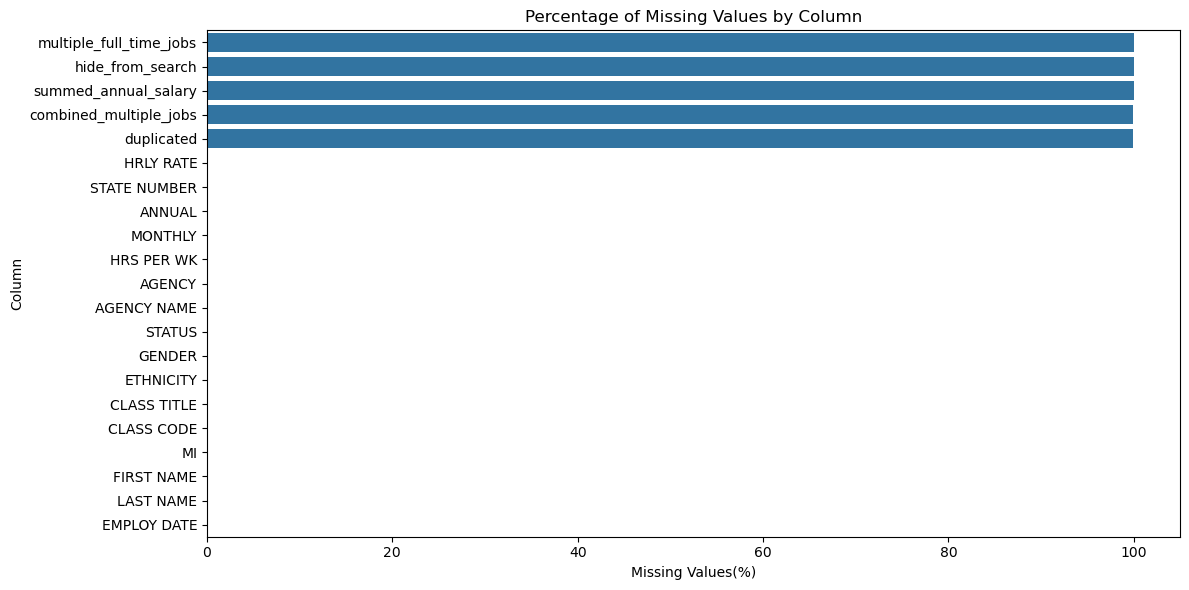

In [11]:
plt.figure(figsize=(12,6))

missing_percent = df.isnull().mean()*100
missing_percent = missing_percent.sort_values(ascending=False)

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)
plt.xlabel("Missing Values(%)")
plt.ylabel("Column")
plt.title("Percentage of Missing Values by Column")
plt.tight_layout()
plt.show()

### Working of the graph

A bar chart was used to display the percentage of missing values in each column. Larger bars represent columns containing more missing values.

### Interpretation
Main salary, employee, agency, and demographic fields contained no missing values.
Several helper columns such as duplicated, multiple_full_time_jobs, combined_multiple_jobs, and summed_annual_salary contained almost all missing values.
These helper fields were not suitable as primary analytical variables.

### Treatment

The main dataset was retained because the important analytical fields were complete. Salary records without ANNUAL values were removed during cleaning.

### Duplicate/Repeated Employee Investigation

In [12]:
duplicate_count = df.duplicated().sum()
print("Number of completely duplicated rows:", duplicate_count)

Number of completely duplicated rows: 0


In [13]:
display(df[df.duplicated()].head())

,AGENCY,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,...,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search


### Duplicate Analysis

A complete row-level duplicate check was performed.

Result
0 completely duplicated rows were found.
Interpretation

The dataset does not contain exact duplicate rows, although some employees have multiple records

### Repeated Employee Analysis

In [14]:
employee_records = (
    df.groupby("STATE NUMBER")
      .agg(
          record_count=("STATE NUMBER", "size"),
          unique_agencies=("AGENCY NAME", "nunique"),
          unique_job_titles=("CLASS TITLE", "nunique"),
          unique_salaries=("ANNUAL", "nunique")
      )
      .reset_index()
)

In [147]:
repeated_employees = employee_records[
    employee_records["record_count"] > 1
].sort_values("record_count", ascending=False)

print("Employees with multiple records:",
      len(repeated_employees))

display(repeated_employees.head(15))

Employees with multiple records: 16


,STATE NUMBER,record_count,unique_agencies,unique_job_titles,unique_salaries
6223,19052,2,2,2,2
19507,59115,2,2,2,2
26206,79455,2,1,2,2
32144,97642,2,2,2,2
42054,127717,2,2,2,2
48362,147334,2,2,2,2
57271,174668,2,1,2,2
63313,193187,2,2,2,2
71863,339371,2,2,2,2
81569,536681,2,2,2,2


In [16]:
employee_records['record_count'].value_counts().sort_index()

record_count
1    149449
2        16
Name: count, dtype: int64

- Conclusion:-
- Case A

Same employee + same agency + same job + same salary

→ potential duplicate record.

- Case B

Same employee + same agency + different job titles

→ potentially legitimate multiple employment.

- Case C

Same employee + same agency + different salary records

→ needs investigation rather than automatic deletion.

### Repeated Employee Analysis

Employees were grouped using STATE NUMBER to identify multiple records.

Result
149,449 employees had one record.
16 employees had two records.
Interpretation

Multiple records do not necessarily represent duplicate data. They may indicate:

Same employee with different agencies.
Same employee with different job titles.
Different salary records.

Therefore, repeated records were investigated rather than automatically deleted.

### Data Cleaning 
The following cleaning steps were performed:

Employment dates were converted to datetime format.
Records without annual salary were removed.
Full-time and part-time employees were identified using hours worked.
Future employment dates were identified as data-quality anomalies.
Salary-derived variables were removed from the predictive model to avoid target leakage.

In [17]:
clean_df = df.copy()

# Converting employment date
clean_df["EMPLOY DATE"] = pd.to_datetime(
    clean_df["EMPLOY DATE"],
    errors="coerce"
)

# Removing rows without target salary
clean_df = clean_df.dropna(subset=["ANNUAL"])

print("Cleaned dataset shape:", clean_df.shape)

Cleaned dataset shape: (149481, 21)


In [18]:
print("Missing Annual:", clean_df["ANNUAL"].isna().sum())
print("Duplicate rows:", clean_df.duplicated().sum())

Missing Annual: 0
Duplicate rows: 0


## Full-Time/ Part-Time Analysis

In [19]:
print(clean_df["HRS PER WK"].describe())

count    149481.000000
mean         39.714918
std           2.323855
min           1.000000
25%          40.000000
50%          40.000000
75%          40.000000
max          70.000000
Name: HRS PER WK, dtype: float64


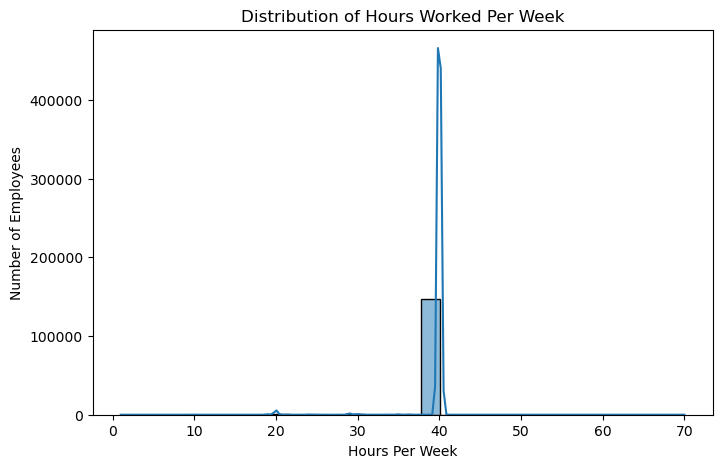

In [145]:
plt.figure(figsize=(8,5))

sns.histplot(
    clean_df["HRS PER WK"],
    bins=30,
    kde=True
)

plt.title("Distribution of Hours Worked Per Week")
plt.xlabel("Hours Per Week")
plt.ylabel("Number of Employees")
plt.show()

In [ ]:
#Comparing a $40,000 part-time annual record with a $100,000 full-time position can distort salary analysis.

- Graph working

A histogram with a KDE curve was used to show the distribution of weekly working hours.

- Interpretation

The distribution is strongly concentrated around 40 hours per week, indicating that most records represent full-time employment.

Full-time employees were used for salary outlier and several business analyses to make salary comparisons more consistent.Graph working

In [22]:
clean_df["FULL_TIME_FLAG"] = np.where(
    clean_df["HRS PER WK"] >= 35,
    "Full-Time",
    "Part-Time"
)

clean_df["FULL_TIME_FLAG"].value_counts()

FULL_TIME_FLAG
Full-Time    147119
Part-Time      2362
Name: count, dtype: int64

In [23]:
model_base = clean_df[
    clean_df["FULL_TIME_FLAG"] == "Full-Time"
].copy()

## Salary Distribution
A histogram with KDE was used to examine the distribution of annual salaries.

- Interpretation:-  Most salaries are concentrated in the lower-to-middle salary ranges.
A smaller number of employees receive substantially higher salaries.
The distribution is positively skewed because of high-salary positions.

- A log-transformed salary distribution was also examined to reduce the effect of extreme values and better understand the underlying distribution.

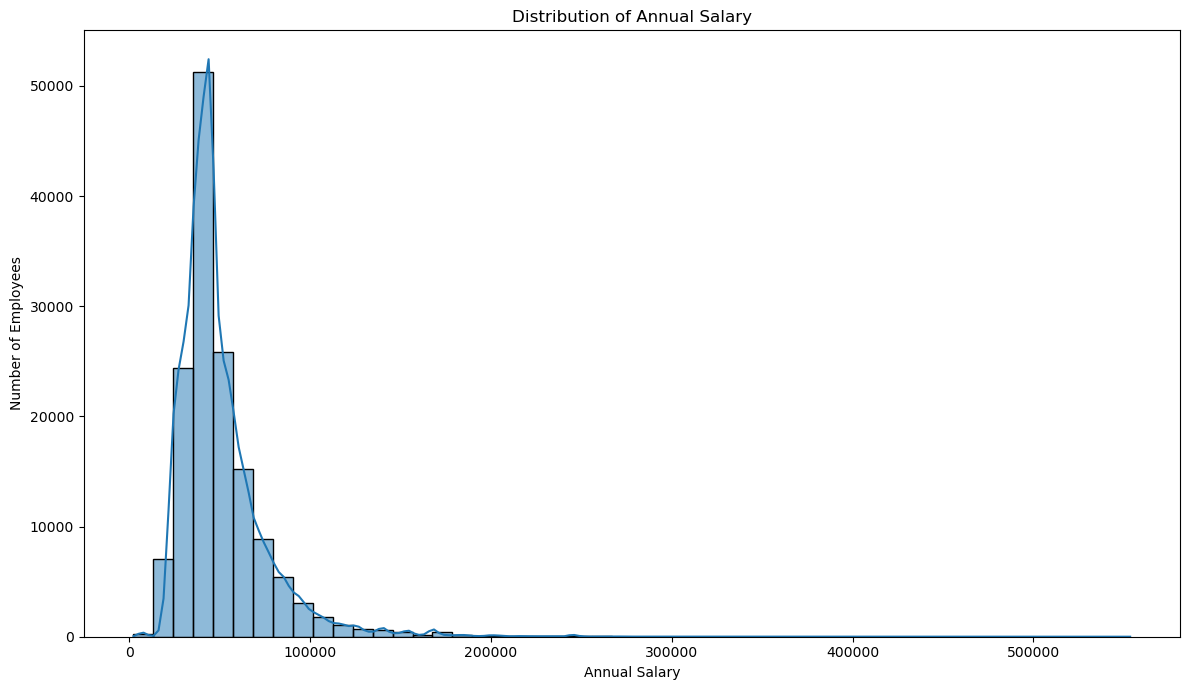

In [134]:
plt.figure(figsize=(12,7))

sns.histplot(
    model_base["ANNUAL"],
    bins=50,
    kde=True
)

plt.title("Distribution of Annual Salary")
plt.xlabel("Annual Salary")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

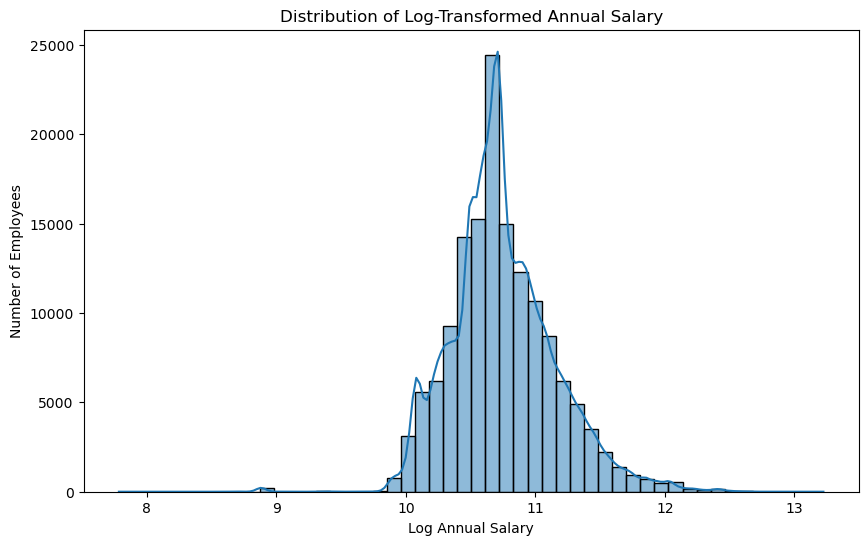

In [25]:
model_base["LOG_ANNUAL"] = np.log1p(model_base["ANNUAL"])

plt.figure(figsize=(10,6))

sns.histplot(
    model_base["LOG_ANNUAL"],
    bins=50,
    kde=True
)

plt.title("Distribution of Log-Transformed Annual Salary")
plt.xlabel("Log Annual Salary")
plt.ylabel("Number of Employees")
plt.show()

## Salary Outlier Analysis:-
The IQR method was used to identify unusually low or high salaries.

 Q1 = $36,238.08, 
 Q3 = $58,398.96, 
 IQR = $22,160.88, 
Upper outlier boundary = $91,640.28

In [26]:
Q1 = model_base["ANNUAL"].quantile(0.25)
Q3 = model_base["ANNUAL"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 36238.08
Q3: 58398.96
IQR: 22160.879999999997
Lower Bound: 2996.7600000000093
Upper Bound: 91640.28


In [27]:
salary_outliers = model_base[
    (model_base["ANNUAL"] < lower_bound) |
    (model_base["ANNUAL"] > upper_bound)
].copy()

print("Number of salary outliers:", len(salary_outliers))

display(
    salary_outliers[
        [
            "STATE NUMBER",
            "FIRST NAME",
            "LAST NAME",
            "AGENCY NAME",
            "CLASS TITLE",
            "ANNUAL"
        ]
    ].sort_values("ANNUAL", ascending=False).head(20)
)

Number of salary outliers: 8595


,STATE NUMBER,FIRST NAME,LAST NAME,AGENCY NAME,CLASS TITLE,ANNUAL
83851,372291,JAMES,WILLSON,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,CHIEF SCIENTIFIC OFFICER ...,553500.00
144232,24680,CHARLES,TULL,EMPLOYEES RETIREMENT SYSTEM ...,DIRECTOR OF INVESTMENTS ...,450000.00
14793,121522,JASE,AUBY,TEACHER RETIREMENT SYSTEM ...,CHIEF INVESTMENT OFFICER ...,450000.00
15154,124553,ERIC,LANG,TEACHER RETIREMENT SYSTEM ...,SENIOR MANAGING DIRECTOR ...,391999.92
136727,7792,BARNEY,TIMMINS III,TEXAS EDUCATION AGENCY ...,PSF CHIEF INVESTMENT OFFICER ...,384375.00
15041,147935,BRIAN,GUTHRIE,TEACHER RETIREMENT SYSTEM ...,EXECUTIVE DIRECTOR ...,355141.44
15539,14408,DALE,WEST,TEACHER RETIREMENT SYSTEM ...,SENIOR MANAGING DIRECTOR ...,344000.04
84769,90927,JAMES,BASS,TEXAS DEPARTMENT OF TRANSPORTATION ...,EXECUTIVE DIRECTOR ...,343999.92
144262,126804,PORTER,WILSON,EMPLOYEES RETIREMENT SYSTEM ...,EXECUTIVE DIRECTOR FOR ERS ...,316116.96
15349,113006,NEIL,RANDALL,TEACHER RETIREMENT SYSTEM ...,MANAGING DIRECTOR ...,315000.00


- Result
1. Full-time employees analyzed: 147,119
2. Salary outliers: 8,595 (5.84%)
3. High-salary outliers: 8,594
4. Low-salary outliers: 1

- Interpretation

Most outliers were high-salary employees, including senior executive, investment, scientific, and specialized positions.

The single low outlier had an annual salary of $2,400 and should be investigated for possible data-quality issues.

Outliers were not automatically removed because an extreme salary can represent legitimate compensation.

### Agencies
Agency-level salary statistics were calculated using:

1. Employee count
2. Average salary
3. Median salary
4. Minimum salary
5. Maximum salary

Agencies with fewer than 10 employees were excluded from the salary ranking to avoid unstable averages.

In [28]:
clean_df['AGENCY NAME'].value_counts().head(15)

AGENCY NAME
HEALTH AND HUMAN SERVICES COMMISSION                  36667
TEXAS DEPARTMENT OF CRIMINAL JUSTICE                  35926
TEXAS DEPARTMENT OF TRANSPORTATION                    13099
DEPARTMENT OF FAMILY AND PROTECTIVE SERVICES          12588
DEPARTMENT OF PUBLIC SAFETY                           10097
TEXAS WORKFORCE COMMISSION                             4653
OFFICE OF THE ATTORNEY GENERAL                         4141
DEPARTMENT OF STATE HEALTH SERVICES                    3129
PARKS AND WILDLIFE DEPARTMENT                          3060
COMPTROLLER OF PUBLIC ACCOUNTS                         2748
TEXAS COMMISSION ON ENVIRONMENTAL QUALITY              2693
TEXAS JUVENILE JUSTICE DEPARTMENT                      2055
TEXAS DEPARTMENT OF INSURANCE                          1278
COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECTION      1033
TEXAS EDUCATION AGENCY                                  967
Name: count, dtype: int64

### Agency Salary Analysis 

In [29]:
agency_salary = (
    model_base.groupby("AGENCY NAME")
    .agg(
        Employee_Count=("ANNUAL", "count"),
        Average_Salary=("ANNUAL", "mean"),
        Median_Salary=("ANNUAL", "median"),
        Minimum_Salary=("ANNUAL", "min"),
        Maximum_Salary=("ANNUAL", "max")
    )
    .reset_index()
)

In [30]:
agency_salary_filtered = agency_salary[
    agency_salary["Employee_Count"] >= 10
].sort_values(
    "Average_Salary",
    ascending=False
)

display(agency_salary_filtered.head(15))

,AGENCY NAME,Employee_Count,Average_Salary,Median_Salary,Minimum_Salary,Maximum_Salary
17,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",635,154710.013417,153999.96,111999.96,168000.0
110,TREASURY SAFEKEEPING TRUST COMPANY ...,70,118709.497714,106062.00,38400.00,240000.0
12,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,33,117206.127273,74476.68,60000.00,553500.0
36,FOURTEENTH COURT OF APPEALS DISTRICT ...,40,112452.993000,107686.44,48000.00,187800.0
35,FIRST COURT OF APPEALS DISTRICT ...,37,110183.380541,107686.44,55620.00,187800.0
111,TWELFTH COURT OF APPEALS DISTRICT ...,15,108816.656000,102750.00,36000.00,187800.0
68,SEVENTH COURT OF APPEALS DISTRICT ...,18,108744.466667,101000.04,57500.04,187800.0
69,SIXTH COURT OF APPEALS DISTRICT ...,15,107096.000000,105600.00,59400.00,187800.0
80,TENTH COURT OF APPEALS DISTRICT ...,14,105258.942857,102612.54,48000.00,187800.0
34,FIFTH COURT OF APPEALS DISTRICT ...,55,104008.662545,99999.96,36999.84,187800.0


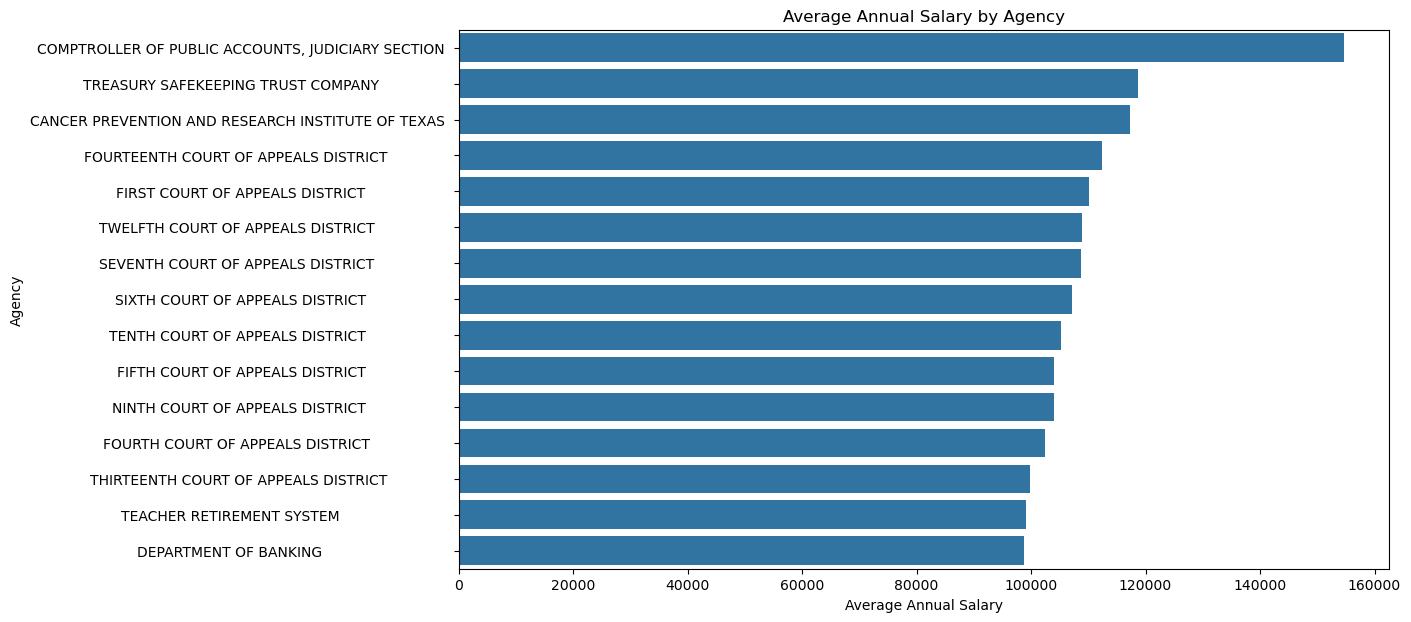

In [31]:
top_agencies = agency_salary_filtered.head(15)

plt.figure(figsize=(12,7))

sns.barplot(
    data=top_agencies,
    y="AGENCY NAME",
    x="Average_Salary"
)

plt.title("Average Annual Salary by Agency")
plt.xlabel("Average Annual Salary")
plt.ylabel("Agency")
plt.show()

### Takeaway

After applying a minimum employee-count threshold, the chart shows the agencies 
with the highest observed average annual salaries. The minimum-count filter was 
used to prevent agencies with only a few employees from dominating the ranking.

- Graph working

A horizontal bar chart compares average annual salaries across the selected agencies.

- Interpretation

The graph shows considerable variation in average salary between agencies. Agencies with specialized, executive, judicial, or investment-related positions tend to have higher average salaries.

## Role/Class Title Analysis
Salary statistics were also calculated for individual job titles.

Roles with at least 10 employees were considered for comparison.

In [32]:
role_salary = (
    model_base.groupby("CLASS TITLE")
    .agg(
        Employee_Count=("ANNUAL", "count"),
        Average_Salary=("ANNUAL", "mean"),
        Median_Salary=("ANNUAL", "median"),
        Minimum_Salary=("ANNUAL", "min"),
        Maximum_Salary=("ANNUAL", "max")
    )
    .reset_index()
)

In [33]:
role_salary_filtered = role_salary[
    role_salary["Employee_Count"] >= 10
].sort_values(
    "Average_Salary",
    ascending=False
)

display(role_salary_filtered.head(10))

,CLASS TITLE,Employee_Count,Average_Salary,Median_Salary,Minimum_Salary,Maximum_Salary
1056,PSYCHIATRIST IV ...,20,259735.458000,260000.04,210000.12,270000.00
1055,PSYCHIATRIST III ...,88,245608.075909,245000.04,244999.92,251652.00
972,PORTFOLIO MANAGER V ...,23,238705.043478,234999.96,204115.68,276815.88
947,PHYSICIAN IV ...,13,238031.575385,237383.28,205056.00,276816.96
379,DEPUTY DIRECTOR III ...,12,236353.560000,247846.20,198999.96,276816.96
378,DEPUTY DIRECTOR II ...,22,223701.600000,228850.08,169992.00,249999.96
971,PORTFOLIO MANAGER IV ...,33,206616.290909,207999.96,173350.20,228404.16
946,PHYSICIAN III ...,33,204455.640000,204512.16,169448.28,231369.00
377,DEPUTY DIRECTOR I ...,85,190383.255529,187425.00,136986.36,228774.96
211,CHIEF JUSTICE ...,15,185789.992000,187800.00,156499.92,204600.00


- Job titles were grouped and ranked using average salary.

- Interpretation

High-paying roles included positions such as:

1. Psychiatrist IV
2. Psychiatrist III
3. Portfolio Manager V
4. Physician IV
5. Deputy Director roles
6. Chief Justice

This demonstrates that job role is an important factor associated with salary differences.

## Manager VS Employee Wage Disparity
- What departments/roles have the biggest wage disparities between managers and employees?
- Because the dataset did not contain an official manager field, manager status was approximated using job-title keywords such as:

manager, director, supervisor, and chief.

Only agencies with at least 5 managers and 5 employees were analyzed.

In [34]:
clean_df["MANAGER_FLAG"] = np.where(
    clean_df["CLASS TITLE"].str.contains(
        "manager|director|supervisor|chief",
        case=False,
        na=False
    ),
    "Manager",
    "Employee"
)

In [35]:
manager_analysis = clean_df[
    clean_df["FULL_TIME_FLAG"] == "Full-Time"
].copy()

In [36]:
manager_counts = (
    manager_analysis
    .groupby(["AGENCY NAME", "MANAGER_FLAG"])
    .size()
    .unstack(fill_value=0)
)

valid_agencies = manager_counts[
    (manager_counts.get("Manager", 0) >= 5) &
    (manager_counts.get("Employee", 0) >= 5)
].index

- Result
1. Valid agencies: 61
2. Records analyzed: 144,149

- Largest observed gaps included:

1. CPRIT: approximately $133,790 (184.26%)
2. Teacher Retirement System: approximately $91,873
3. Office of Governor: approximately $85,214

In [37]:
valid_data = manager_analysis[
    manager_analysis["AGENCY NAME"].isin(valid_agencies)
]

salary_comparison = (
    valid_data
    .groupby(["AGENCY NAME", "MANAGER_FLAG"])["ANNUAL"]
    .mean()
    .unstack()
)

salary_comparison["Wage_Gap"] = (
    salary_comparison["Manager"] -
    salary_comparison["Employee"]
)

salary_comparison = salary_comparison.sort_values(
    "Wage_Gap",
    ascending=False
)

display(salary_comparison.head(15))

MANAGER_FLAG,Employee,Manager,Wage_Gap
AGENCY NAME,,,
CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS,72609.621818,206399.138182,133789.516364
TEACHER RETIREMENT SYSTEM,79675.214545,171548.534286,91873.319740
OFFICE OF THE GOVERNOR,71215.962783,156430.178182,85214.215399
EMPLOYEES RETIREMENT SYSTEM,73862.719579,151138.584578,77275.864999
TEXAS LOTTERY COMMISSION,65205.397500,141914.318571,76708.921071
DEPARTMENT OF BANKING,92034.110189,166570.065000,74535.954811
TREASURY SAFEKEEPING TRUST COMPANY,95690.726809,165747.855652,70057.128844
ALCOHOLIC BEVERAGE COMMISSION,58549.560000,125527.090000,66977.530000
PUBLIC UTILITY COMMISSION OF TEXAS,70997.711538,135862.552500,64864.840962


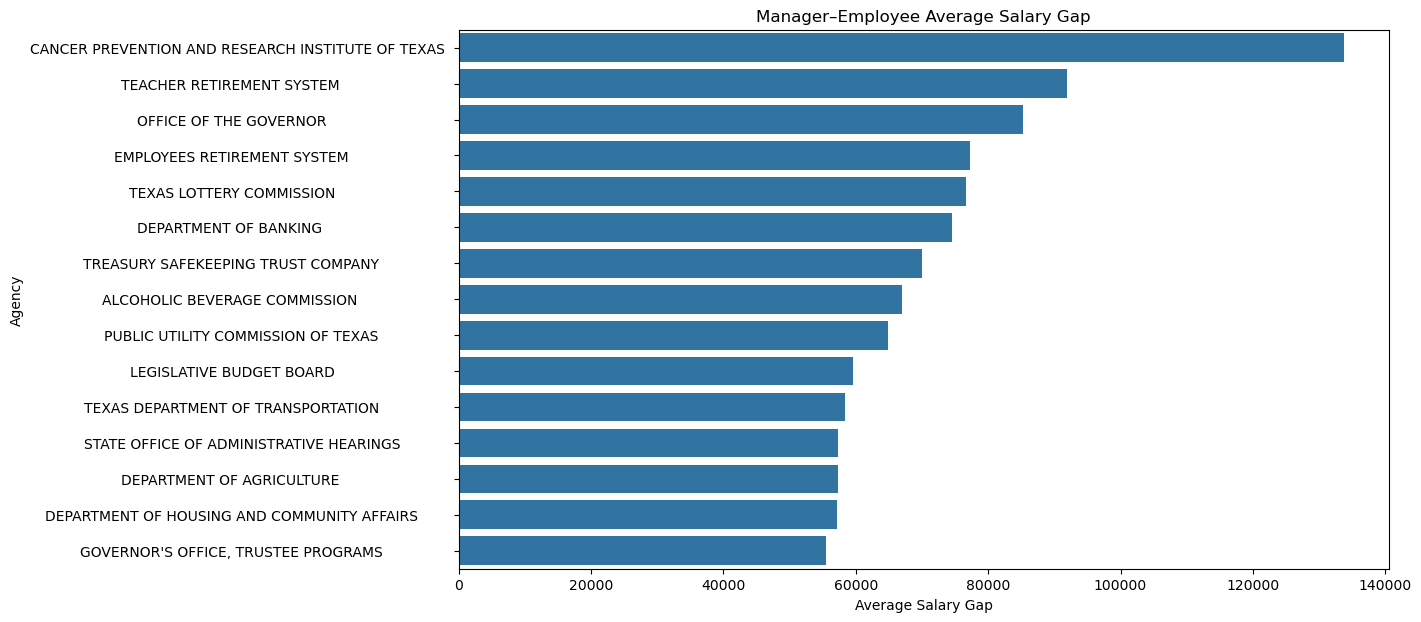

In [38]:
top_gap = salary_comparison.head(15).reset_index()

plt.figure(figsize=(12,7))

sns.barplot(
    data=top_gap,
    y="AGENCY NAME",
    x="Wage_Gap"
)

plt.title("Manager–Employee Average Salary Gap")
plt.xlabel("Average Salary Gap")
plt.ylabel("Agency")
plt.show()

- Graph working

A horizontal bar chart compares the average salary difference between manager and employee groups for the top agencies.

- Interpretation

Manager-designated roles generally had higher average salaries than employee-designated roles. However, this represents a title-based comparison, not an official organizational hierarchy.

### Manager Classification Limitation

Manager status was approximated using job-title keywords because the supplied 
dataset does not contain a dedicated managerial-status field. Therefore, the 
manager-versus-employee comparison should be interpreted as a job-title-based 
analysis rather than an official organizational hierarchy.

## Time-Based Analysis

In [39]:
clean_df["EMPLOY YEAR"] = clean_df["EMPLOY DATE"].dt.year

In [137]:
valid_time_df = clean_df[
    clean_df["EMPLOY YEAR"].between(1976, 2020)
].copy()

In [138]:
yearly_salary = (
    valid_time_df.groupby("EMPLOY YEAR")
    .agg(
        Average_Salary=("ANNUAL", "mean"),
        Median_Salary=("ANNUAL", "median"),
        Headcount=("ANNUAL", "count")
    )
    .reset_index()
)

In [139]:
yearly_salary_filtered = yearly_salary[
    yearly_salary["Headcount"] >= 10
]

In [140]:
valid_time_df = clean_df[
    clean_df["EMPLOY YEAR"].between(1976, 2020)
].copy()

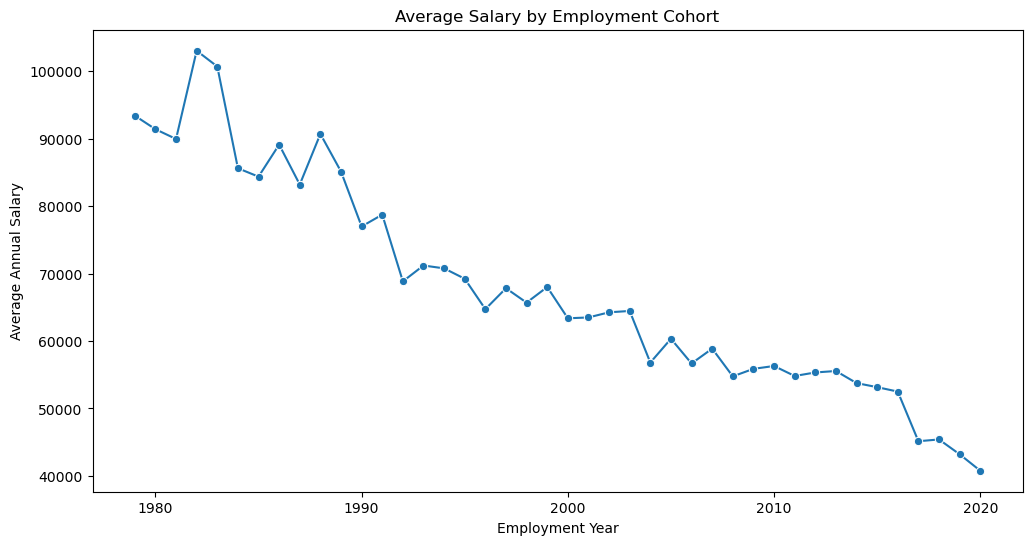

In [141]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=yearly_salary_filtered,
    x="EMPLOY YEAR",
    y="Average_Salary",
    marker="o"
)

plt.title("Average Salary by Employment Cohort")
plt.xlabel("Employment Year")
plt.ylabel("Average Annual Salary")
plt.show()

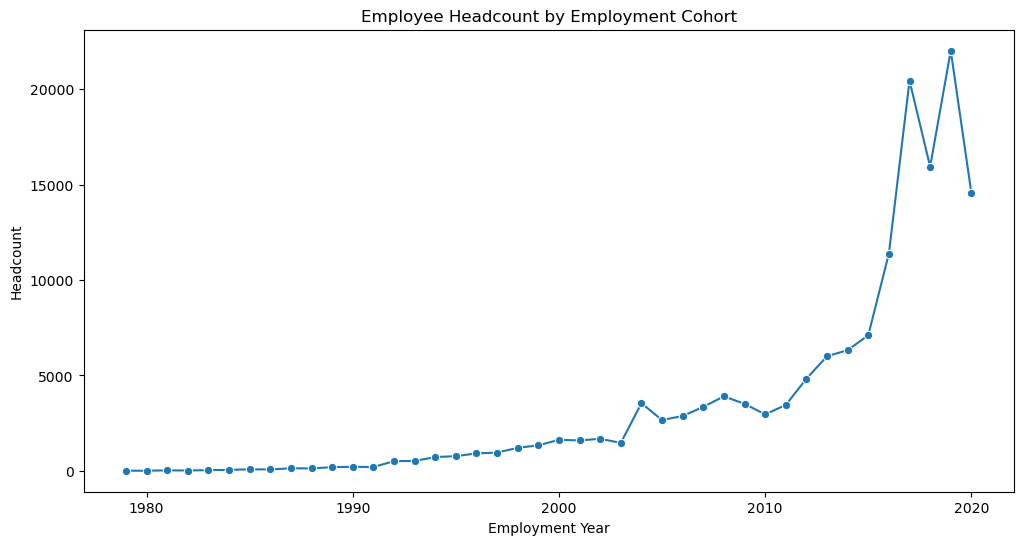

In [142]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=yearly_salary_filtered,
    x="EMPLOY YEAR",
    y="Headcount",
    marker="o"
)

plt.title("Employee Headcount by Employment Cohort")
plt.xlabel("Employment Year")
plt.ylabel("Headcount")
plt.show()

### Tenure Feature

In [46]:
valid_dates = clean_df.loc[
    clean_df["EMPLOY YEAR"].between(1976, 2020),
    "EMPLOY DATE"
]

reference_date = valid_dates.max()

clean_df["TENURE_YEARS"] = (
    (reference_date - clean_df["EMPLOY DATE"]).dt.days / 365.25
).clip(lower=0)

## Correlation Analysis

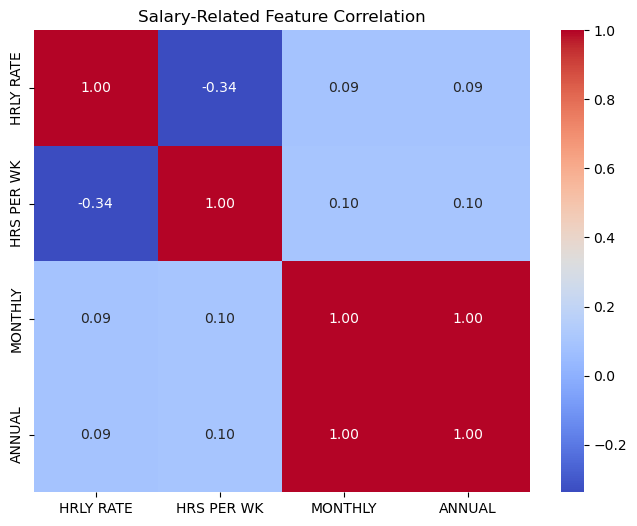

In [135]:
correlation_columns = [
    "HRLY RATE",
    "HRS PER WK",
    "MONTHLY",
    "ANNUAL"
]

corr = clean_df[correlation_columns].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Salary-Related Feature Correlation")
plt.show()

A correlation heatmap was used to examine relationships between:

- Hourly Rate
- Hours per Week
- Monthly Salary
- Annual Salary

Graph working:- 

The heatmap displays correlation coefficients between numerical salary-related variables.

Values closer to +1 indicate strong positive relationships, while values near 0 indicate weak linear relationships.

Interpretation:- 

Strong relationships were observed between salary-related variables, particularly annual salary and variables mathematically derived from salary.

This led to the target-leakage investigation before model training.

### Critical Target Leakage Fix

In [48]:
model_df = clean_df.drop(
    columns=[
        "MONTHLY",
        "HRLY RATE",
        "summed_annual_salary",
        "multiple_full_time_jobs",
        "hide_from_search",
        "combined_multiple_jobs",
        "duplicated"
    ],
    errors="ignore"
)

### Removing Identifier

In [49]:
identifier_columns = [
    "FIRST NAME",
    "LAST NAME",
    "MI",
    "STATE NUMBER",
    "CLASS CODE",
    "AGENCY"
]

model_df = model_df.drop(
    columns=identifier_columns,
    errors="ignore"
)

The dataset contains variables directly related to annual salary, such as:

- MONTHLY
- HRLY RATE
- summed_annual_salary

Using these variables could allow the model to indirectly calculate the target instead of genuinely learning salary patterns.

Technique used:- 

These variables were removed before model training.

Reason:- 

This prevents artificially high model performance and makes the prediction results more realistic.

- These can allow the model to memorize individuals or create unnecessary high-dimensional encoding.
- Gender and ethnicity can be useful for descriptive fairness analysis, but their use as predictive features should be carefully justified. A salary prediction model using protected attributes can reproduce or encode historical disparities.

## Feature Engineering :
The following features were excluded from prediction:

- First Name
- Last Name
- Middle Initial
- State Number
- Class Code
- Agency code
- Salary-derived variables

Reason:

These identifiers may cause memorization, excessive dimensionality, or leakage.

New features included:

- Employment Year
- Tenure
- Full-Time/Part-Time Flag
- Manager Flag

Categorical features were retained where they could provide useful job or organizational information.

In [50]:
model_df["EMPLOY YEAR"] = (
    pd.to_datetime(
        model_df["EMPLOY DATE"],
        errors="coerce"
    ).dt.year
)

In [51]:
model_df["TENURE_YEARS"] = clean_df["TENURE_YEARS"]

In [52]:
model_df = model_df.drop(
    columns=["EMPLOY DATE"],
    errors="ignore"
)

### Target and Feature 

In [53]:
TARGET = "ANNUAL"

X = model_df.drop(columns=[TARGET])
y = model_df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (149481, 10)
y shape: (149481,)


## Groupe Based Train/Test-Split
A GroupShuffleSplit was used with STATE NUMBER as the grouping variable.

Result:
- Training records: 119,586
- Testing records: 29,895
- Test size: 20%

Reason:

Grouping by employee identifier prevents records belonging to the same employee from being distributed across both training and testing sets.

In [54]:
groups = clean_df["STATE NUMBER"]

In [55]:
# Keep employee ID separately for grouping
groups = clean_df["STATE NUMBER"].loc[model_df.index]

print("Number of groups:", groups.nunique())
print("Number of observations:", len(groups))

Number of groups: 149465
Number of observations: 149481


In [56]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 119586
Testing rows: 29895


## Preprocessing
Numerical variables
- Missing values → median imputation
- Scaling → StandardScaler

Categorical variables
- Missing values → most frequent value
- Encoding → One-Hot Encoding
- Unknown test categories → ignored using handle_unknown='ignore'

The original 10 model features expanded to approximately 1,505 encoded features.

In [143]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['HRS PER WK', 'EMPLOY YEAR', 'TENURE_YEARS']
Categorical features: ['AGENCY NAME', 'CLASS TITLE', 'ETHNICITY', 'GENDER', 'STATUS', 'FULL_TIME_FLAG', 'MANAGER_FLAG']


In [144]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Train Multiple Model

In [ ]:
# linear Regression Model - Linear Regression is a supervised learning algorithm that models 
#                       the relationship between the target variable and input features using a linear equation.

#Purpose:- 
# It was used as a baseline regression model and to understand how employee, agency, role
#                      and employment-related features are associated with annual salary.

In [60]:
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Linear Regression completed successfully.")

Linear Regression completed successfully.


In [61]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression
MAE : 3326.0203555608887
RMSE: 6174.8563536783895
R²  : 0.9403239448547531


In [62]:
# Decision Tree Model- A Decision Tree Regression model predicts a continuous value by repeatedly splitting 
#                          the data into groups based on feature conditions

# Purpose:
# It was used to capture non-linear relationships and 
# decision-based salary patterns that a simple linear model may not capture.

In [63]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        max_depth=15,
        min_samples_leaf=5,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

In [64]:
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree")
print("MAE :", dt_mae)
print("RMSE:", dt_rmse)
print("R²  :", dt_r2)

Decision Tree
MAE : 9319.245113646699
RMSE: 15522.651593063269
R²  : 0.6228811783065654


In [148]:
# Random Forest :- Random Forest is an ensemble learning algorithm that
#            combines predictions from multiple decision trees to produce a more stable prediction

# Purpose:-
# It was used to test whether combining several decision 
# trees could improve salary prediction and reduce the limitations of a single tree.

In [66]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [67]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest
MAE : 9234.330726450818
RMSE: 15053.009774609744
R²  : 0.6453556250463


In [149]:
# Gradient Boosting:- Gradient Boosting is an ensemble technique that builds models sequentially, with each new model attempting to reduce 
#                        the errors made by the previous models.

# Purpose:- 
# It was used to test whether a boosting approach could capture complex non-linear
# relationships and improve salary predictions.

In [69]:
gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        min_samples_leaf=5,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

In [70]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R²  :", gb_r2)

Gradient Boosting
MAE : 10582.932261801292
RMSE: 15553.451445360955
R²  : 0.6213831446350861


### Model Comparison 

In [71]:
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [72]:
results = []

results.append(evaluate_model(
    "Linear Regression",
    y_test,
    linear_pred
))

results.append(evaluate_model(
    "Decision Tree",
    y_test,
    dt_pred
))

results.append(evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
))

results.append(evaluate_model(
    "Gradient Boosting",
    y_test,
    gb_pred
))

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

results_df

,Model,MAE,RMSE,R2
0,Linear Regression,3326.020356,6174.856354,0.940324
1,Random Forest,9234.330726,15053.009775,0.645356
2,Decision Tree,9319.245114,15522.651593,0.622881
3,Gradient Boosting,10582.932262,15553.451445,0.621383


### Model Comparison Visualization

In [73]:
# MAE Comparison-

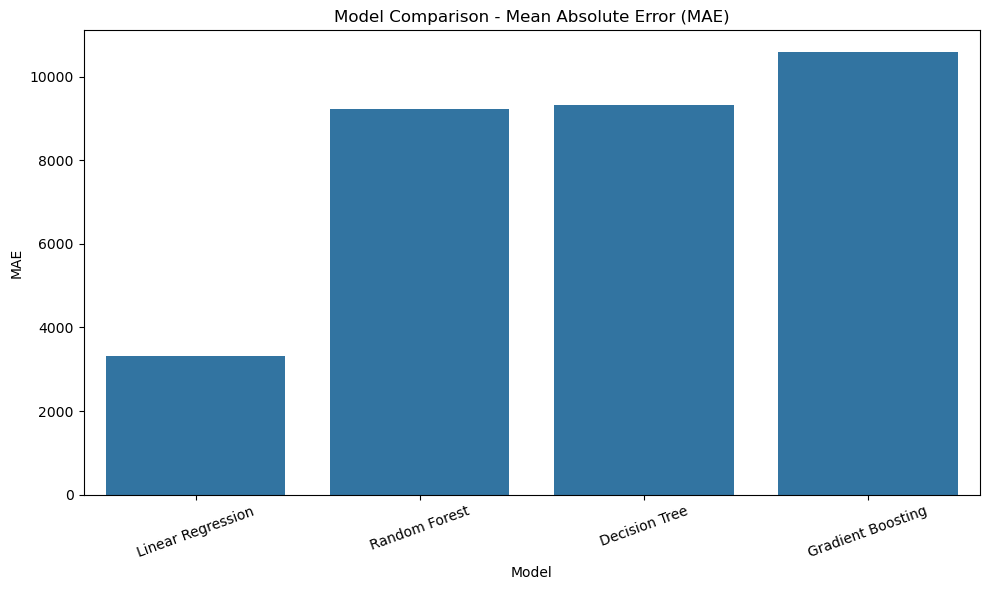

In [74]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Model Comparison - Mean Absolute Error (MAE)")
plt.xlabel("Model")
plt.ylabel("MAE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

- Interpretation: Lower MAE indicates smaller average prediction errors.

In [75]:
# RMSE Comparison-

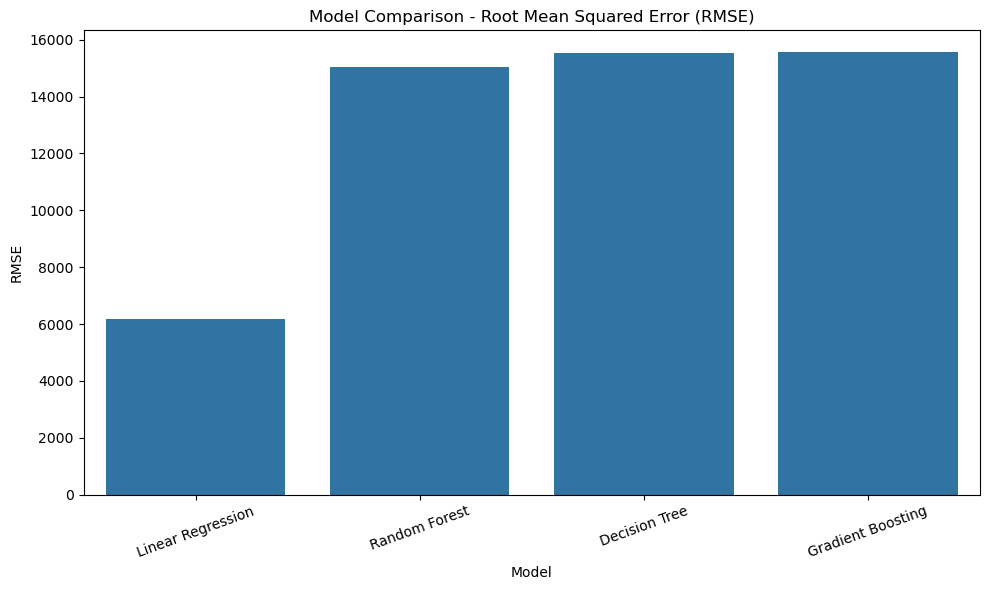

In [76]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison - Root Mean Squared Error (RMSE)")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

- Interpretation: Lower RMSE indicates better prediction performance, with larger errors receiving greater weight.

In [77]:
# R² Comparison- 

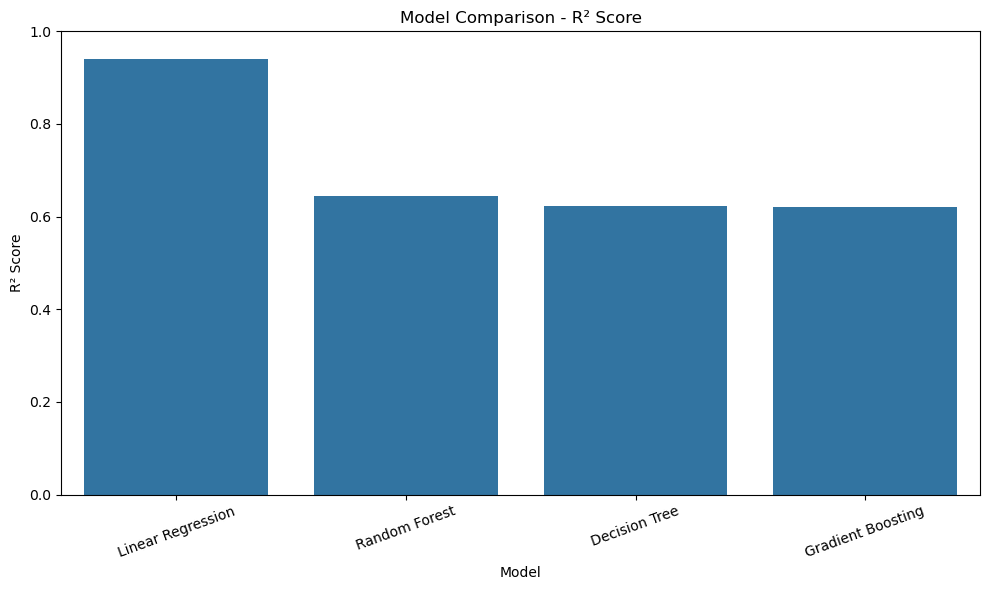

In [78]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2"
)

plt.title("Model Comparison - R² Score")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

- Interpretation: Higher R² indicates that the model explains more of the variation in annual salary.

### Final Model Selection

In [79]:
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(),
    "Model"
]

print("Best Model based on RMSE:", best_model_name)

Best Model based on RMSE: Linear Regression


In [80]:
best_r2_model = results_df.loc[
    results_df["R2"].idxmax(),
    "Model"
]

print("Best Model based on R²:", best_r2_model)

Best Model based on R²: Linear Regression


### Observation
Model Comparison: Four regression models—Linear Regression, Decision Tree, Random Forest, and Gradient Boosting—were trained and evaluated using the same group-based train-test split. Linear Regression achieved the lowest MAE (3,325.55) and RMSE (6,175.38), along with the highest R² (0.9403). Therefore, Linear Regression was selected as the final model based on its performance on the held-out test set.

## Actual VS Predicted Salary 

In [81]:
actual_predicted_df = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": linear_pred
})

actual_predicted_df.head()

,Actual Salary,Predicted Salary
0,37800.00,34785.314394
1,80000.04,62772.029907
2,32331.12,44853.723803
3,102000.00,91666.545750
4,130200.00,93227.672577


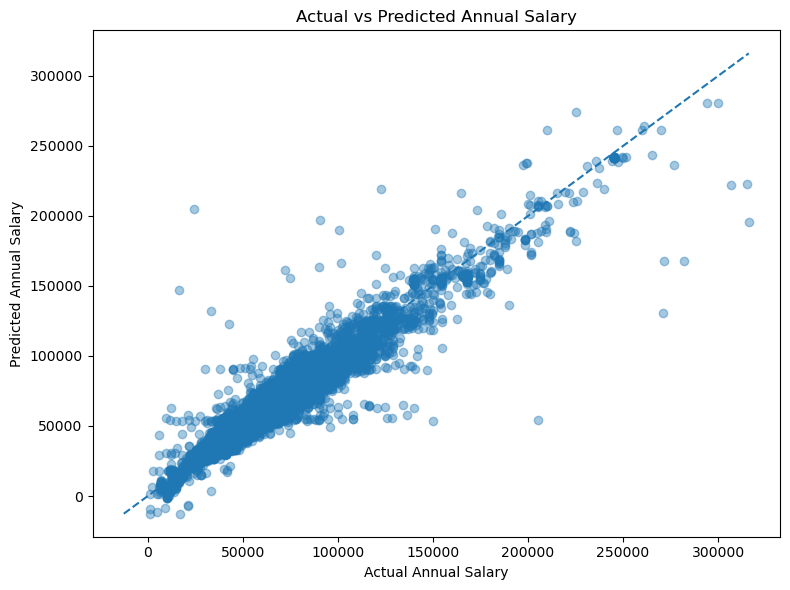

In [82]:
plt.figure(figsize=(8, 6))

plt.scatter(
    actual_predicted_df["Actual Salary"],
    actual_predicted_df["Predicted Salary"],
    alpha=0.4
)

# Perfect prediction reference line
min_value = min(
    actual_predicted_df["Actual Salary"].min(),
    actual_predicted_df["Predicted Salary"].min()
)

max_value = max(
    actual_predicted_df["Actual Salary"].max(),
    actual_predicted_df["Predicted Salary"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Annual Salary")
plt.xlabel("Actual Annual Salary")
plt.ylabel("Predicted Annual Salary")
plt.tight_layout()
plt.show()

-- The dashed diagonal represents perfect predictions.

- Points close to the diagonal → predictions are close to actual salaries.
- Points above the diagonal → model overpredicts salary.
- Points below the diagonal → model underpredicts salary.
- A wide spread around the diagonal → larger prediction errors.

## Calculate Prediction Errors/Residual Analysis
### Residual = Actual − Predicted

In [83]:
actual_predicted_df["Residual"] = (
    actual_predicted_df["Actual Salary"] -
    actual_predicted_df["Predicted Salary"]
)

actual_predicted_df.head()

,Actual Salary,Predicted Salary,Residual
0,37800.00,34785.314394,3014.685606
1,80000.04,62772.029907,17228.010093
2,32331.12,44853.723803,-12522.603803
3,102000.00,91666.545750,10333.454250
4,130200.00,93227.672577,36972.327423


In [84]:
actual_predicted_df["Residual"].describe()

count     29895.000000
mean        -12.938280
std        6174.946077
min     -180807.928769
25%       -1805.878507
50%        -122.942204
75%        1575.540789
max      150845.555793
Name: Residual, dtype: float64

### Residual Distribution

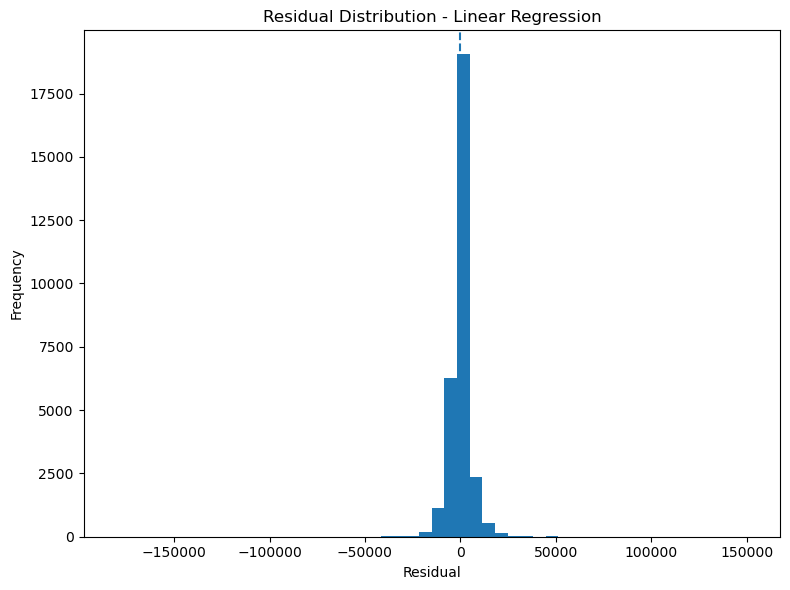

In [85]:
plt.figure(figsize=(8, 6))

plt.hist(
    actual_predicted_df["Residual"],
    bins=50
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title("Residual Distribution - Linear Regression")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

-- Interpretation

Ideally, residuals should be reasonably centered around 0.

- Residual > 0 → actual salary is higher than predicted.
- Residual < 0 → actual salary is lower than predicted.
- A distribution centered around zero indicates that the model isn't consistently overpredicting or underpredicting.

### Residuals vs Predicted Salary

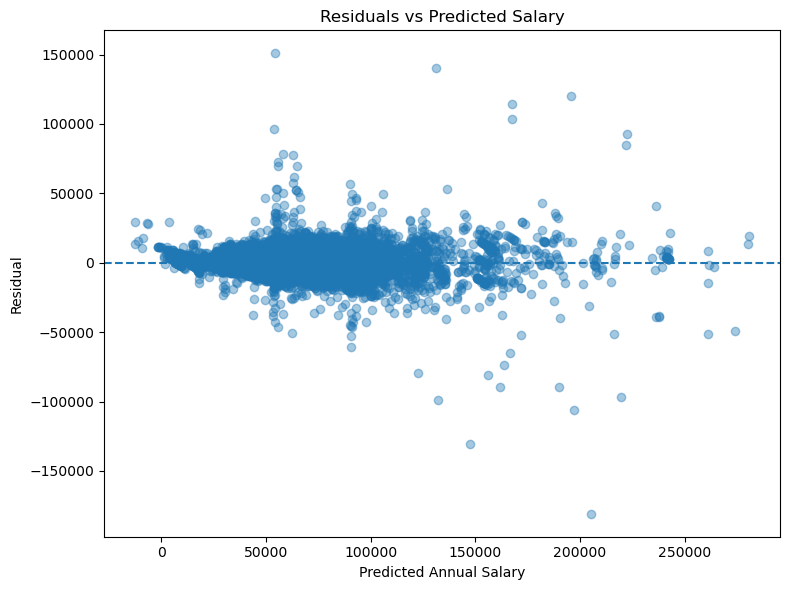

In [86]:
plt.figure(figsize=(8, 6))

plt.scatter(
    linear_pred,
    actual_predicted_df["Residual"],
    alpha=0.4
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Residuals vs Predicted Salary")
plt.xlabel("Predicted Annual Salary")
plt.ylabel("Residual")
plt.tight_layout()
plt.show()

In [87]:
# Mean Residual Check
mean_residual = actual_predicted_df["Residual"].mean()

print("Mean Residual:", mean_residual)

Mean Residual: -12.938280185242009


- Interpretation : the model has very little overall directional bias. A negative value means the model slightly overpredicts on average, but is $12.89
- is tiny compared with the salary scale and the RMSE of about $6,175.

### Residual Analysis: 
The residuals were centered close to zero, with a mean residual of −12.89, indicating minimal overall prediction bias. The middle 50% of residuals ranged from approximately −$1,802 to $1,572. However, extreme residuals ranged from approximately −$180,871 to $150,894, indicating that the model has larger prediction errors for a small number of observations. The difference between MAE ($3,325.55) and RMSE ($6,175.38) further indicates the presence of relatively large individual prediction errors.

### Largest Prediction Errors

In [88]:
actual_predicted_df["Absolute Error"] = (
    actual_predicted_df["Residual"].abs()
)

largest_errors = actual_predicted_df.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

largest_errors

,Actual Salary,Predicted Salary,Residual,Absolute Error
27510,24505.92,205313.848769,-180807.928769,180807.928769
28364,205008.00,54162.444207,150845.555793,150845.555793
16231,271082.88,131028.190132,140054.689868,140054.689868
11789,16475.28,147348.659548,-130873.379548,130873.379548
28849,316116.96,195740.528723,120376.431277,120376.431277
16598,281874.96,167573.152883,114301.807117,114301.807117
28542,90699.96,197006.128793,-106306.168793,106306.168793
3024,271320.00,167525.393820,103794.606180,103794.606180
29711,33053.16,131975.618782,-98922.458782,98922.458782
6619,122499.96,219459.075173,-96959.115173,96959.115173


## Error Analysis by Salary Band

In [89]:
# Create salary bands based on actual salary
actual_predicted_df["Salary Band"] = pd.cut(
    actual_predicted_df["Actual Salary"],
    bins=[0, 30000, 50000, 75000, 100000, np.inf],
    labels=[
        "Below 30K",
        "30K-50K",
        "50K-75K",
        "75K-100K",
        "Above 100K"
    ]
)

In [90]:
# Calculate error metrics for each salary band
salary_band_error = (
    actual_predicted_df
    .groupby("Salary Band", observed=False)
    .agg(
        Count=("Actual Salary", "count"),
        MAE=("Absolute Error", "mean"),
        RMSE=("Residual", lambda x: np.sqrt(np.mean(x**2))),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
)

salary_band_error

,Salary Band,Count,MAE,RMSE,Mean_Residual
0,Below 30K,4059,2080.088338,4934.936294,-660.817053
1,30K-50K,14837,1957.448703,3411.043209,-581.896611
2,50K-75K,7455,4306.881955,6017.039939,-150.929503
3,75K-100K,2229,6910.974071,9500.267064,2397.723600
4,Above 100K,1315,10975.868732,17381.733749,5102.448739


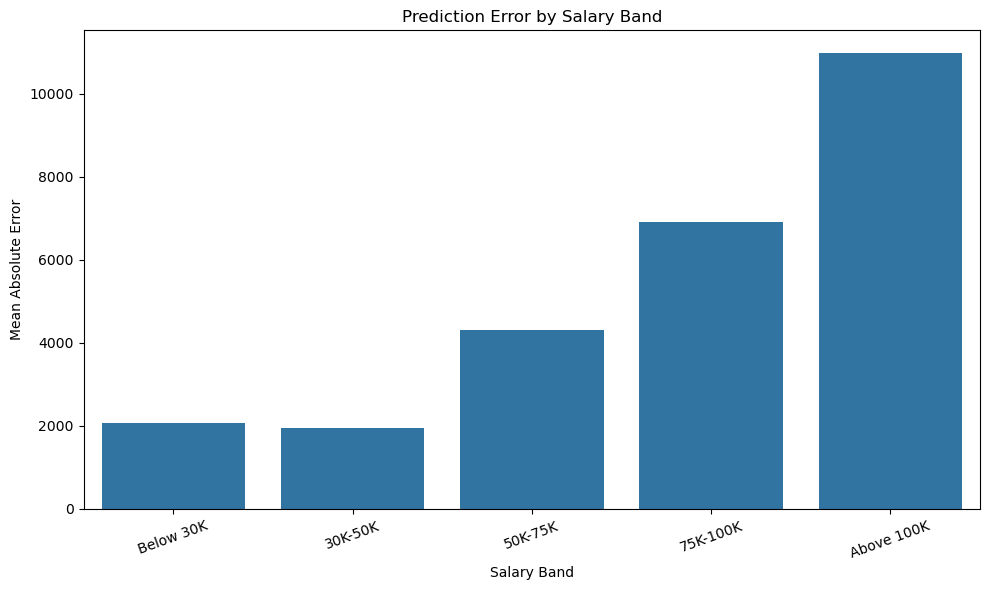

In [91]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=salary_band_error,
    x="Salary Band",
    y="MAE"
)

plt.title("Prediction Error by Salary Band")
plt.xlabel("Salary Band")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

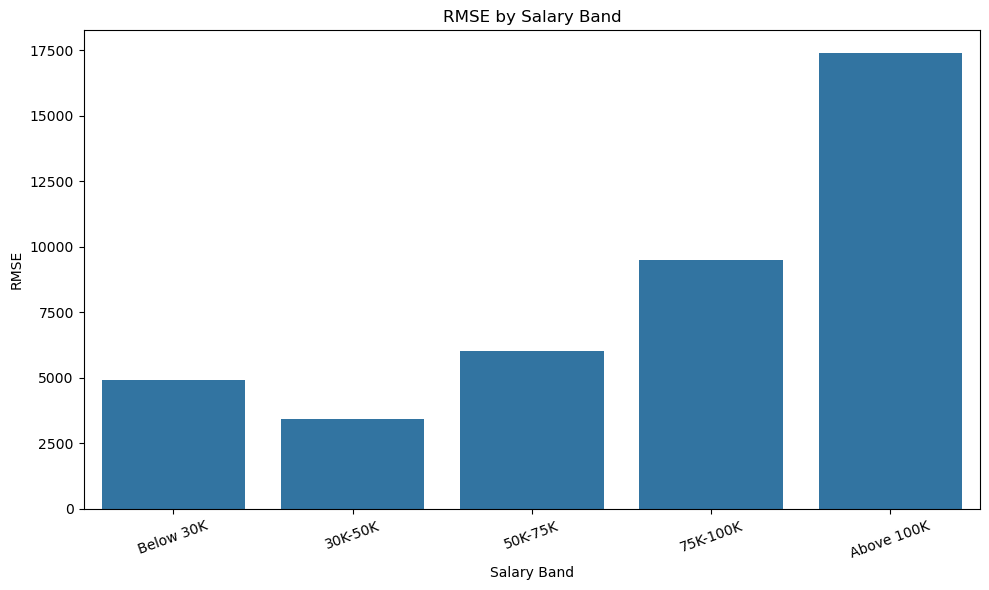

In [92]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=salary_band_error,
    x="Salary Band",
    y="RMSE"
)

plt.title("RMSE by Salary Band")
plt.xlabel("Salary Band")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Error Analysis by Salary Band

* Model errors were evaluated across five salary ranges.
* **Below $30K:** MAE ≈ **$2,081**
* **$30K–$50K:** MAE ≈ **$1,957**
* **$50K–$75K:** MAE ≈ **$4,306**
* **$75K–$100K:** MAE ≈ **$6,910**
* **Above $100K:** MAE ≈ **$10,976**
* Prediction errors generally increased as salary increased, with the highest-salary group showing the greatest error.


## Coefficient Analysis

In [93]:
# Get the fitted preprocessing pipeline
fitted_preprocessor = linear_model.named_steps["preprocessor"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Linear Regression coefficients
coefficients = linear_model.named_steps["model"].coef_

# Create coefficient dataframe
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Absolute coefficient for sorting
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

In [94]:
# Display largest positive and negative coefficients
top_positive = (
    coefficient_df
    .sort_values("Coefficient", ascending=False)
    .head(15)
)
print("Top Positive Coefficients:")
display(top_positive)

Top Positive Coefficients:


,Feature,Coefficient,Absolute_Coefficient
325,cat__CLASS TITLE_CHIEF SCIENTIFIC OFFICER ...,358475.564719,358475.564719
501,cat__CLASS TITLE_DIRECTOR OF INVESTMENTS ...,230829.808551,230829.808551
1136,cat__CLASS TITLE_PSYCHIATRIST IV ...,203907.843374,203907.843374
629,cat__CLASS TITLE_FIRST ASST ATTORNEY GENERAL ...,201621.753616,201621.753616
475,cat__CLASS TITLE_DEPUTY COMPTROLLER ...,194674.871867,194674.871867
474,cat__CLASS TITLE_DEPUTY COMMISSIONER ...,193512.615768,193512.615768
1129,cat__CLASS TITLE_PSF CHIEF INVESTMENT OFFICER ...,190102.832078,190102.832078
1135,cat__CLASS TITLE_PSYCHIATRIST III ...,184723.266438,184723.266438
1030,cat__CLASS TITLE_PHYSICIAN IV ...,177406.335224,177406.335224
481,cat__CLASS TITLE_DEPUTY DIRECTOR IV ...,155903.966306,155903.966306


In [95]:
top_negative = (
    coefficient_df
    .sort_values("Coefficient", ascending=True)
    .head(15)
)
print("\nTop Negative Coefficients:")
display(top_negative)


Top Negative Coefficients:


,Feature,Coefficient,Absolute_Coefficient
924,cat__CLASS TITLE_MED TECHNOLOGIST TRAINEE ...,-145276.092206,145276.092206
1390,"cat__CLASS TITLE_TEACHER,PRINCIPALS,SUPERVISOR...",-133355.741402,133355.741402
870,cat__CLASS TITLE_LICENSED VOCA NURSE TRAINEE ...,-133309.374016,133309.374016
1188,cat__CLASS TITLE_REGISTERED NURSE TRAINEE ...,-132108.700537,132108.700537
354,"cat__CLASS TITLE_COMMISS, SABINE RIVER COMPACT...",-123774.561011,123774.561011
356,cat__CLASS TITLE_COMMISSION MEMBERS ...,-122037.214163,122037.214163
986,cat__CLASS TITLE_OFFICE MANAGER ...,-120643.765476,120643.765476
351,"cat__CLASS TITLE_COMMISS, CANADIAN RIVER COMPA...",-120165.195264,120165.195264
713,cat__CLASS TITLE_HOURLY/SUBSTITUTES ...,-106918.960474,106918.960474
352,"cat__CLASS TITLE_COMMISS, RED RIVER COMPACT ...",-106198.843711,106198.843711


### Linear Regression Coefficient Analysis

* Coefficients were analyzed to identify features strongly associated with predicted salary.
* High positive associations included **Chief Scientific Officer, Director Investments, and Psychiatrist IV**.
* Negative associations were mainly linked to **trainee, assistant, and substitute positions**.
* Coefficients represent associations from the **one-hot encoded features** and should not be interpreted as direct salary differences.



### Employee-level prediction analysis table

In [96]:
# Creating an employee-level prediction analysis table

prediction_analysis = X_test.copy()

prediction_analysis["Actual Salary"] = y_test.values
prediction_analysis["Predicted Salary"] = linear_pred

prediction_analysis["Residual"] = (
    prediction_analysis["Actual Salary"] -
    prediction_analysis["Predicted Salary"]
)

prediction_analysis["Absolute Error"] = (
    prediction_analysis["Residual"].abs()
)

# Display the employees with the largest prediction errors
largest_prediction_errors = (
    prediction_analysis
    .sort_values("Absolute Error", ascending=False)
    .head(10)
)

largest_prediction_errors[
    [
        "CLASS TITLE",
        "AGENCY NAME",
        "HRS PER WK",
        "Actual Salary",
        "Predicted Salary",
        "Residual",
        "Absolute Error"
    ]
]

,CLASS TITLE,AGENCY NAME,HRS PER WK,Actual Salary,Predicted Salary,Residual,Absolute Error
137600,PSYCHIATRIST III ...,SCHOOL FOR THE DEAF ...,4.00,24505.92,205313.848769,-180807.928769,180807.928769
141800,ELECTED OFFICIALS STAFF ...,HOUSE OF REPRESENTATIVES ...,40.00,205008.00,54162.444207,150845.555793,150845.555793
81936,"COMMISSIONER, DSHS ...",DEPARTMENT OF STATE HEALTH SERVICES ...,40.00,271082.88,131028.190132,140054.689868,140054.689868
59462,PHYSICIAN III ...,HEALTH AND HUMAN SERVICES COMMISSION ...,4.15,16475.28,147348.659548,-130873.379548,130873.379548
144262,EXECUTIVE DIRECTOR FOR ERS ...,EMPLOYEES RETIREMENT SYSTEM ...,40.00,316116.96,195740.528723,120376.431277,120376.431277
83846,EXECUTIVE DIRECTOR ...,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,40.00,281874.96,167573.152883,114301.807117,114301.807117
142622,ASSISTANT DIRECTOR OF OPERATIO ...,SUNSET ADVISORY COMMISSION ...,40.00,90699.96,197006.128793,-106306.168793,106306.168793
15186,LEAD INVESTMENT ATTORNEY ...,TEACHER RETIREMENT SYSTEM ...,40.00,271320.00,167525.393820,103794.606180,103794.606180
148575,"COMMISS, PECOS RIVER COMPACT ...",TEXAS COMMISSION ON ENVIRONMENTAL QUALITY ...,40.00,33053.16,131975.618782,-98922.458782,98922.458782
33247,PSYCHIATRIST III ...,HEALTH AND HUMAN SERVICES COMMISSION ...,20.00,122499.96,219459.075173,-96959.115173,96959.115173


### Employee-Level Prediction Error Analysis

* Examined employees with the **largest differences between actual and predicted salaries**.
* Large errors were mainly associated with **senior/specialized roles and unusual work-hour records**.
* The largest error was approximately **$180,871** for a Psychiatrist III record.
* Several executive, commissioner, physician, and investment-related roles also showed large errors.
* These records were flagged for **business or data-quality investigation**, rather than automatically removed.



# Business Findings -

## 1. Who are the outliers in the salaries?

In [97]:
# the outlier summary- 
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Total Full-Time Employees:", len(model_base))
print("Total Salary Outliers:", len(salary_outliers))

print(
    "Outlier Percentage:",
    round(len(salary_outliers) / len(model_base) * 100, 2),
    "%"
)

Lower Bound: 2996.7600000000093
Upper Bound: 91640.28
Total Full-Time Employees: 147119
Total Salary Outliers: 8595
Outlier Percentage: 5.84 %


In [98]:
# Separate high and low salary outliers
low_salary_outliers = salary_outliers[
    salary_outliers["ANNUAL"] < lower_bound
].copy()

high_salary_outliers = salary_outliers[
    salary_outliers["ANNUAL"] > upper_bound
].copy()

print("Low Salary Outliers:", len(low_salary_outliers))
print("High Salary Outliers:", len(high_salary_outliers))

Low Salary Outliers: 1
High Salary Outliers: 8594


In [99]:
# Examine the highest-paid outliers

In [100]:
highest_salary_outliers = (
    high_salary_outliers
    .sort_values("ANNUAL", ascending=False)
    .head(5)
)

highest_salary_outliers[
    [
        "CLASS TITLE",
        "AGENCY NAME",
        "HRS PER WK",
        "ANNUAL"
    ]
]

,CLASS TITLE,AGENCY NAME,HRS PER WK,ANNUAL
83851,CHIEF SCIENTIFIC OFFICER ...,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,40.0,553500.00
144232,DIRECTOR OF INVESTMENTS ...,EMPLOYEES RETIREMENT SYSTEM ...,40.0,450000.00
14793,CHIEF INVESTMENT OFFICER ...,TEACHER RETIREMENT SYSTEM ...,40.0,450000.00
15154,SENIOR MANAGING DIRECTOR ...,TEACHER RETIREMENT SYSTEM ...,40.0,391999.92
136727,PSF CHIEF INVESTMENT OFFICER ...,TEXAS EDUCATION AGENCY ...,40.0,384375.00


In [101]:
# Examine the lowest-paid outliers

In [102]:
lowest_salary_outliers = (
    low_salary_outliers
    .sort_values("ANNUAL", ascending=True)
    .head(5)
)

lowest_salary_outliers[
    [
        "CLASS TITLE",
        "AGENCY NAME",
        "HRS PER WK",
        "ANNUAL"
    ]
]

,CLASS TITLE,AGENCY NAME,HRS PER WK,ANNUAL
142316,ELECTED OFFICIALS STAFF ...,HOUSE OF REPRESENTATIVES ...,40.0,2400.0


In [103]:
# Visualize the salary outliers

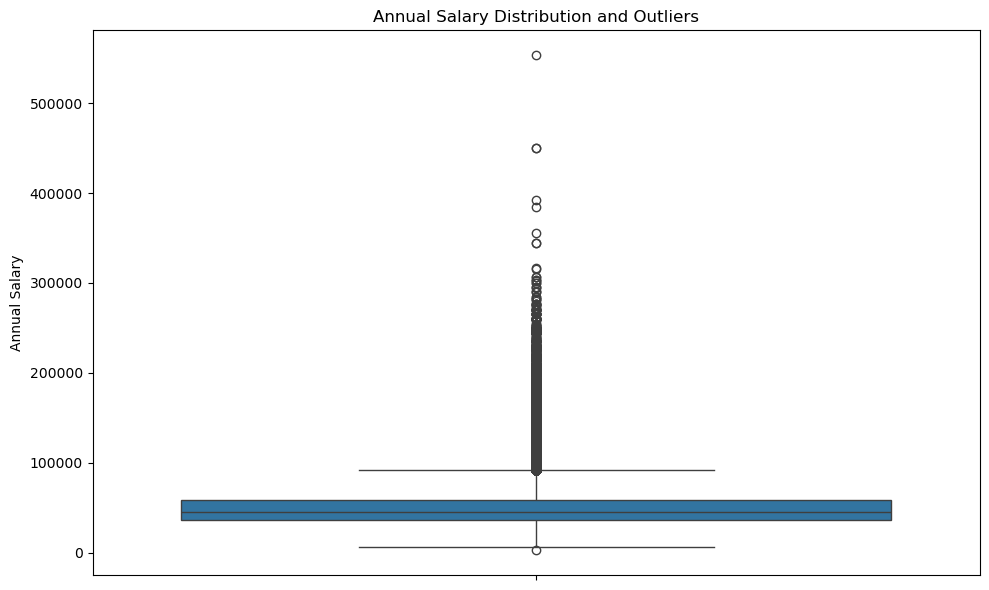

In [104]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    y=model_base["ANNUAL"]
)

plt.title("Annual Salary Distribution and Outliers")
plt.ylabel("Annual Salary")

plt.tight_layout()
plt.show()

In [105]:
# Identify which job titles have the most outliers

In [106]:
outlier_by_role = (
    salary_outliers
    .groupby("CLASS TITLE")
    .agg(
        Outlier_Count=("ANNUAL", "count"),
        Average_Salary=("ANNUAL", "mean")
    )
    .sort_values("Outlier_Count", ascending=False)
    .head(10)
    .reset_index()
)

outlier_by_role

,CLASS TITLE,Outlier_Count,Average_Salary
0,DIRECTOR II ...,646,109349.622353
1,DIRECTOR III ...,576,119369.047500
2,"DISTRICT JUDGE, ACTIVE ...",472,155635.352797
3,MGR V ...,460,101150.128435
4,DIRECTOR IV ...,371,131615.811429
5,DIRECTOR I ...,267,101481.603596
6,ATTORNEY IV ...,234,104707.178974
7,SYSTEMS ANALYST VI ...,215,102928.442791
8,DIRECTOR VI ...,205,159612.516878
9,ENGINEER V ...,204,98095.144706


### Salary Outlier Analysis

* Analysis covered **147,119 full-time employees** using the IQR method.
* Identified **8,595 salary outliers (5.84%)**.
* **8,594 were high-salary outliers** and only **1 was a low-salary outlier**.
* The highest outliers included senior investment, executive, and scientific positions.
* The low outlier had an annual salary of **$2,400** and may require data validation.
* Outliers were not automatically removed because they may represent legitimate compensation.


## 2. What departments/roles have the biggest wage disparities between managers and employees?

In [107]:
# Prepare the manager/employee dataset

In [108]:
# Use full-time employees for a fair salary comparison
manager_analysis = clean_df[
    clean_df["FULL_TIME_FLAG"] == "Full-Time"
].copy()

# Count managers and employees in each agency
manager_counts = (
    manager_analysis
    .groupby(["AGENCY NAME", "MANAGER_FLAG"])
    .size()
    .unstack(fill_value=0)
)

manager_counts.head()

MANAGER_FLAG,Employee,Manager
AGENCY NAME,,
ALCOHOLIC BEVERAGE COMMISSION,608,24
BOARD OF ARCHITECTURAL EXAMINERS,16,1
BOARD OF CHIROPRACTIC EXAMINERS,9,1
BOARD OF DENTAL EXAMINERS,53,3
BOARD OF EXAMINERS OF PSYCHOLOGISTS,13,0


In [109]:
# Keep agencies with sufficient observations

In [110]:
valid_agencies = manager_counts[
    (manager_counts.get("Manager", 0) >= 5) &
    (manager_counts.get("Employee", 0) >= 5)
].index

valid_data = manager_analysis[
    manager_analysis["AGENCY NAME"].isin(valid_agencies)
].copy()

print("Total valid agencies:", len(valid_agencies))
print("Total records analyzed:", len(valid_data))

Total valid agencies: 61
Total records analyzed: 144149


In [111]:
# Calculate average manager and employee salaries

In [112]:
salary_comparison = (
    valid_data
    .groupby(["AGENCY NAME", "MANAGER_FLAG"])
    .agg(
        Average_Salary=("ANNUAL", "mean"),
        Employee_Count=("ANNUAL", "count")
    )
    .unstack()
)
salary_comparison.head()

Average_Salary  \
MANAGER_FLAG                                             Employee   
AGENCY NAME                                                         
ALCOHOLIC BEVERAGE COMMISSION                        58549.560000   
BOARD OF NURSE EXAMINERS                             60879.550099   
BOARD OF PUBLIC ACCOUNTANCY                          62034.392308   
CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS    72609.621818   
COMMISSION ON LAW ENFORCEMENT OFFICER STANDARDS AN   49222.253023   

                                                                   \
MANAGER_FLAG                                              Manager   
AGENCY NAME                                                         
ALCOHOLIC BEVERAGE COMMISSION                       125527.090000   
BOARD OF NURSE EXAMINERS                            103784.085000   
BOARD OF PUBLIC ACCOUNTANCY                         104360.256000   
CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS   206399.138182   
COMMISSION ON LAW ENFORCEMENT OFFICER STANDARDS AN   85332.480000   

                                                   Employee_Count          
MANAGER_FLAG                                             Employee Manager  
AGENCY NAME                                                                
ALCOHOLIC BEVERAGE COMMISSION                                 608      24  
BOARD OF NURSE EXAMINERS                                      101       8  
BOARD OF PUBLIC ACCOUNTANCY                                    26      10  
CANCER PREVENTION AND RESEARCH INSTITUTE OF TEXAS              22      11  
COMMISSION ON LAW ENFORCEMENT OFFICER STANDARDS AN             43       8

In [113]:
salary_comparison.columns = [
    f"{col[1]}_{col[0]}"
    for col in salary_comparison.columns
]

salary_comparison = salary_comparison.reset_index()

salary_comparison.head()

,AGENCY NAME,Employee_Average_Salary,Manager_Average_Salary,Employee_Employee_Count,Manager_Employee_Count
0,ALCOHOLIC BEVERAGE COMMISSION ...,58549.560000,125527.090000,608,24
1,BOARD OF NURSE EXAMINERS ...,60879.550099,103784.085000,101,8
2,BOARD OF PUBLIC ACCOUNTANCY ...,62034.392308,104360.256000,26,10
3,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,72609.621818,206399.138182,22,11
4,COMMISSION ON LAW ENFORCEMENT OFFICER STANDARD...,49222.253023,85332.480000,43,8


In [114]:
# Calculate the wage gap

In [115]:
salary_comparison["Wage_Gap"] = (
    salary_comparison["Manager_Average_Salary"]
    - salary_comparison["Employee_Average_Salary"]
)

salary_comparison["Wage_Gap_Percentage"] = (
    salary_comparison["Wage_Gap"]
    / salary_comparison["Employee_Average_Salary"]
) * 100

In [116]:
largest_wage_gaps = (
    salary_comparison
    .sort_values("Wage_Gap", ascending=False)
    .head()
)

largest_wage_gaps[
    [
        "AGENCY NAME",
        "Manager_Employee_Count",
        "Employee_Employee_Count",
        "Manager_Average_Salary",
        "Employee_Average_Salary",
        "Wage_Gap",
        "Wage_Gap_Percentage"
    ]
]

,AGENCY NAME,Manager_Employee_Count,Employee_Employee_Count,Manager_Average_Salary,Employee_Average_Salary,Wage_Gap,Wage_Gap_Percentage
3,CANCER PREVENTION AND RESEARCH INSTITUTE OF TE...,11,22,206399.138182,72609.621818,133789.516364,184.258660
39,TEACHER RETIREMENT SYSTEM ...,168,627,171548.534286,79675.214545,91873.319740,115.309786
25,OFFICE OF THE GOVERNOR ...,22,115,156430.178182,71215.962783,85214.215399,119.656060
15,EMPLOYEES RETIREMENT SYSTEM ...,83,285,151138.584578,73862.719579,77275.864999,104.620931
53,TEXAS LOTTERY COMMISSION ...,28,256,141914.318571,65205.397500,76708.921071,117.641981


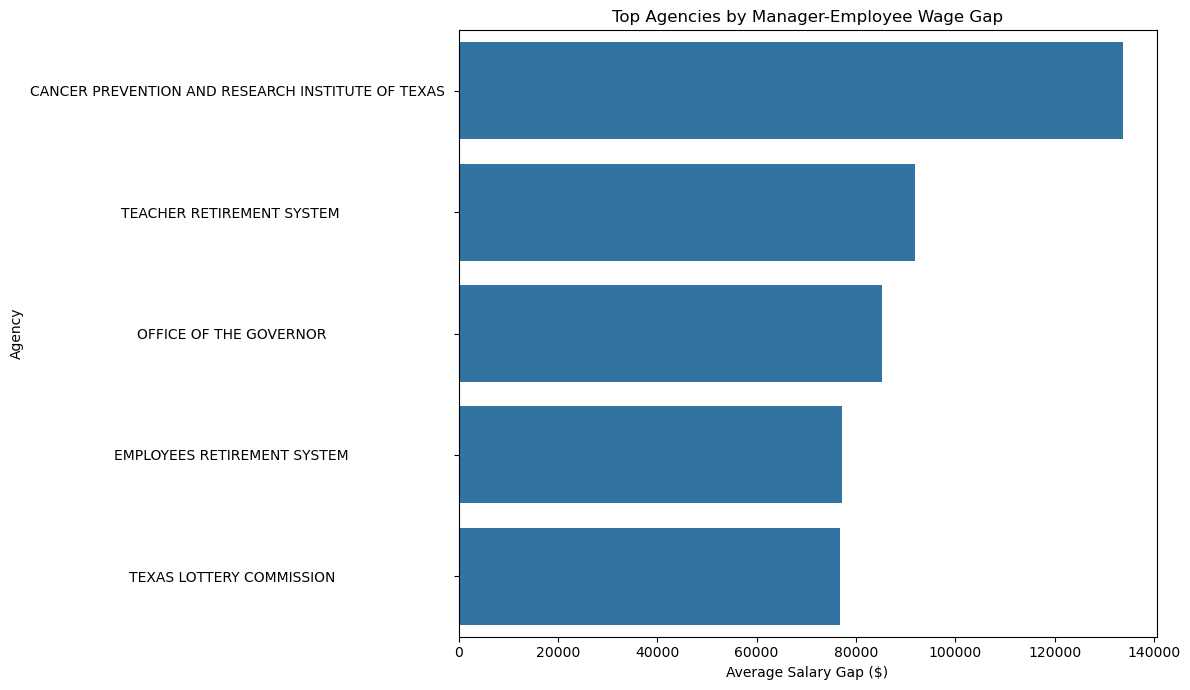

In [117]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=largest_wage_gaps,
    x="Wage_Gap",
    y="AGENCY NAME"
)

plt.title("Top Agencies by Manager-Employee Wage Gap")
plt.xlabel("Average Salary Gap ($)")
plt.ylabel("Agency")

plt.tight_layout()
plt.show()

### Manager vs Employee Wage Disparity

* Analysis was performed for **61 agencies** with at least 5 managers and 5 employees.
* **CPRIT** showed the largest wage gap: approximately **$133,790 (184.26%)**.
* Other notable gaps were observed in the **Teacher Retirement System ($91,873)** and **Office of Governor ($85,214)**.
* Manager salaries were generally higher than employee salaries across the analyzed agencies.
* Manager identification was based on **job-title keywords**, so results should be interpreted as approximate.



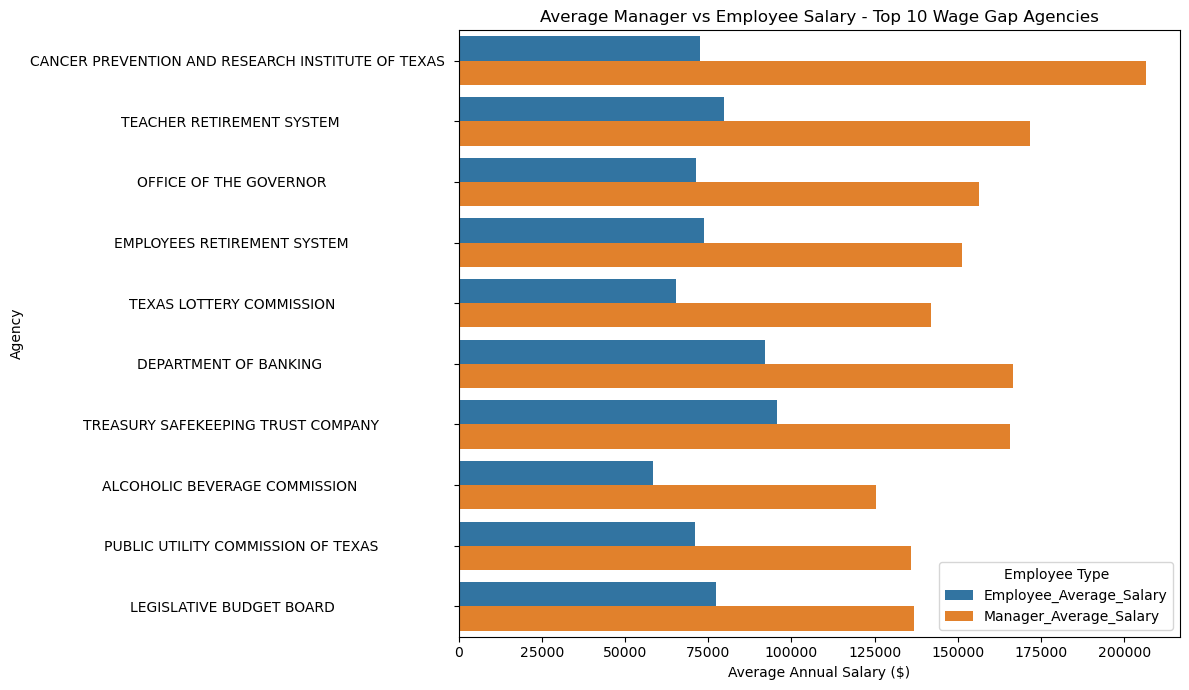

In [118]:
# Select the top 10 agencies by wage gap
top_10_gaps = (
    salary_comparison
    .sort_values("Wage_Gap", ascending=False)
    .head(10)
)

# Reshape data for comparison
comparison_plot = top_10_gaps[
    [
        "AGENCY NAME",
        "Employee_Average_Salary",
        "Manager_Average_Salary"
    ]
].melt(
    id_vars="AGENCY NAME",
    var_name="Employee Type",
    value_name="Average Salary"
)

# Plot
plt.figure(figsize=(12, 7))

sns.barplot(
    data=comparison_plot,
    x="Average Salary",
    y="AGENCY NAME",
    hue="Employee Type"
)

plt.title("Average Manager vs Employee Salary - Top 10 Wage Gap Agencies")
plt.xlabel("Average Annual Salary ($)")
plt.ylabel("Agency")
plt.legend(title="Employee Type")

plt.tight_layout()
plt.show()

## 3. Have salaries and total compensations for some roles/ departments/ head-count changed over time?

In [119]:
# Prepare the data
role_dept_df = clean_df[
    (clean_df["EMPLOY YEAR"] >= 1976) &
    (clean_df["EMPLOY YEAR"] <= 2020)
].copy()

In [120]:
# Department-wise salary and headcount over time

In [121]:
agency_year_analysis = (
    role_dept_df
    .groupby(["AGENCY NAME", "EMPLOY YEAR"])
    .agg(
        Average_Salary=("ANNUAL", "mean"),
        Median_Salary=("ANNUAL", "median"),
        Headcount=("ANNUAL", "count")
    )
    .reset_index()
)

agency_year_analysis.head()

,AGENCY NAME,EMPLOY YEAR,Average_Salary,Median_Salary,Headcount
0,ALCOHOLIC BEVERAGE COMMISSION ...,1981,49268.88,49268.88,1
1,ALCOHOLIC BEVERAGE COMMISSION ...,1987,49268.88,49268.88,1
2,ALCOHOLIC BEVERAGE COMMISSION ...,1989,37602.84,37602.84,1
3,ALCOHOLIC BEVERAGE COMMISSION ...,1991,41380.44,41380.44,2
4,ALCOHOLIC BEVERAGE COMMISSION ...,1992,86494.92,86494.92,1


In [122]:
# Remove very small agency-year groups
agency_year_analysis = agency_year_analysis[
    agency_year_analysis["Headcount"] >= 10
].copy()

In [123]:
# Find agencies with the largest salary variation
agency_salary_change = (
    agency_year_analysis
    .groupby("AGENCY NAME")
    .agg(
        Highest_Average_Salary=("Average_Salary", "max"),
        Lowest_Average_Salary=("Average_Salary", "min"),
        Total_Headcount=("Headcount", "sum"),
        Number_of_Cohorts=("EMPLOY YEAR", "nunique")
    )
    .reset_index()
)

agency_salary_change["Salary_Range"] = (
    agency_salary_change["Highest_Average_Salary"]
    - agency_salary_change["Lowest_Average_Salary"]
)

agency_salary_change = agency_salary_change[
    agency_salary_change["Number_of_Cohorts"] >= 5
].sort_values(
    "Salary_Range",
    ascending=False
)

agency_salary_change.head(10)

,AGENCY NAME,Highest_Average_Salary,Lowest_Average_Salary,Total_Headcount,Number_of_Cohorts,Salary_Range
43,TEACHER RETIREMENT SYSTEM ...,157384.020000,72656.669011,762,19,84727.350989
52,TEXAS HIGHER EDUCATION COORDINATING BOARD ...,127047.900000,57277.898182,138,7,69770.001818
16,EMPLOYEES RETIREMENT SYSTEM ...,136946.022857,68874.938462,301,13,68071.084396
14,DEPARTMENT OF PUBLIC SAFETY ...,96185.102400,41499.392316,10065,34,54685.710084
49,TEXAS DEPARTMENT OF TRANSPORTATION ...,96663.682759,42170.490649,13075,37,54493.192109
45,TEXAS COMMISSION ON ENVIRONMENTAL QUALITY ...,97694.124000,45895.148308,2666,31,51798.975692
20,HEALTH AND HUMAN SERVICES COMMISSION ...,84741.770769,35422.958529,36646,19,49318.812240
30,PARKS AND WILDLIFE DEPARTMENT ...,81409.260000,32628.940150,3017,30,48780.319850
21,HOUSE OF REPRESENTATIVES ...,75840.923077,27122.204384,720,15,48718.718693
39,STATE AUDITOR'S OFFICE ...,105131.568000,57551.106667,110,8,47580.461333


In [124]:
# Department headcount changes over time

In [125]:
agency_headcount_change = (
    agency_year_analysis
    .groupby("AGENCY NAME")
    .agg(
        Minimum_Headcount=("Headcount", "min"),
        Maximum_Headcount=("Headcount", "max"),
        Total_Headcount=("Headcount", "sum"),
        Number_of_Cohorts=("EMPLOY YEAR", "nunique")
    )
    .reset_index()
)

agency_headcount_change["Headcount_Change"] = (
    agency_headcount_change["Maximum_Headcount"]
    - agency_headcount_change["Minimum_Headcount"]
)

agency_headcount_change = agency_headcount_change[
    agency_headcount_change["Number_of_Cohorts"] >= 5
].sort_values(
    "Headcount_Change",
    ascending=False
)

agency_headcount_change.head(10)

,AGENCY NAME,Minimum_Headcount,Maximum_Headcount,Total_Headcount,Number_of_Cohorts,Headcount_Change
20,HEALTH AND HUMAN SERVICES COMMISSION ...,26,13206,36646,19,13180
46,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,17,5557,35893,32,5540
10,DEPARTMENT OF FAMILY AND PROTECTIVE SERVICES ...,30,1791,12588,29,1761
49,TEXAS DEPARTMENT OF TRANSPORTATION ...,19,1525,13075,37,1506
60,TEXAS WORKFORCE COMMISSION ...,25,1340,4653,25,1315
14,DEPARTMENT OF PUBLIC SAFETY ...,13,1144,10065,34,1131
28,OFFICE OF THE ATTORNEY GENERAL ...,13,584,4118,32,571
54,TEXAS JUVENILE JUSTICE DEPARTMENT ...,60,586,2055,10,526
15,DEPARTMENT OF STATE HEALTH SERVICES ...,49,503,3129,17,454
45,TEXAS COMMISSION ON ENVIRONMENTAL QUALITY ...,10,335,2666,31,325


In [126]:
# Role-wise salary and headcount over time

In [127]:
role_year_analysis = (
    role_dept_df
    .groupby(["CLASS TITLE", "EMPLOY YEAR"])
    .agg(
        Average_Salary=("ANNUAL", "mean"),
        Median_Salary=("ANNUAL", "median"),
        Headcount=("ANNUAL", "count")
    )
    .reset_index()
)

role_year_analysis = role_year_analysis[
    role_year_analysis["Headcount"] >= 10
].copy()

In [128]:
# Find roles with the largest salary variation
role_salary_change = (
    role_year_analysis
    .groupby("CLASS TITLE")
    .agg(
        Highest_Average_Salary=("Average_Salary", "max"),
        Lowest_Average_Salary=("Average_Salary", "min"),
        Total_Headcount=("Headcount", "sum"),
        Number_of_Cohorts=("EMPLOY YEAR", "nunique")
    )
    .reset_index()
)

role_salary_change["Salary_Range"] = (
    role_salary_change["Highest_Average_Salary"]
    - role_salary_change["Lowest_Average_Salary"]
)

role_salary_change = role_salary_change[
    role_salary_change["Number_of_Cohorts"] >= 5
].sort_values(
    "Salary_Range",
    ascending=False
)

role_salary_change.head(10)

,CLASS TITLE,Highest_Average_Salary,Lowest_Average_Salary,Total_Headcount,Number_of_Cohorts,Salary_Range
131,ELECTED OFFICIALS STAFF ...,69578.778750,28161.072353,482,10,41417.706397
253,LEGISLATIVE PROFESSIONAL ...,69742.574545,38747.384000,131,7,30995.190545
247,LEG. OFFICIAL/ADMINISTRATOR ...,100018.458000,69880.002857,94,5,30138.455143
126,"DISTRICT JUDGE, ACTIVE ...",168000.000000,141187.135385,400,12,26812.864615
178,GAME WARDEN ...,78009.288000,53241.960000,365,17,24767.328000
437,TROOPER ...,79323.000000,54808.381463,2228,25,24514.618537
26,AGENT ...,74163.665455,53241.960000,96,7,20921.705455
89,CORREC OFFICER IV ...,40842.317876,21409.712727,9235,14,19432.605149
123,DIRECTOR IV ...,141353.690000,124413.630000,293,19,16940.060000
289,NATURAL RESOURCES SPEC V ...,78614.640000,62134.691429,119,9,16479.948571


In [129]:
# Find roles with the largest headcount changes
role_headcount_change = (
    role_year_analysis
    .groupby("CLASS TITLE")
    .agg(
        Minimum_Headcount=("Headcount", "min"),
        Maximum_Headcount=("Headcount", "max"),
        Total_Headcount=("Headcount", "sum"),
        Number_of_Cohorts=("EMPLOY YEAR", "nunique")
    )
    .reset_index()
)

role_headcount_change["Headcount_Change"] = (
    role_headcount_change["Maximum_Headcount"]
    - role_headcount_change["Minimum_Headcount"]
)

role_headcount_change = role_headcount_change[
    role_headcount_change["Number_of_Cohorts"] >= 5
].sort_values(
    "Headcount_Change",
    ascending=False
)

role_headcount_change.head(10)

,CLASS TITLE,Minimum_Headcount,Maximum_Headcount,Total_Headcount,Number_of_Cohorts,Headcount_Change
89,CORREC OFFICER IV ...,11,2626,9235,14,2615
91,CORREC OFFCR III ...,10,2368,4705,5,2358
426,TEXAS WORKS ADVISOR II ...,23,809,3643,16,786
60,CHILD PROTECTIVE SVCS SPEC I ...,35,817,1741,5,782
90,CORREC OFFICER V ...,43,772,7873,29,729
254,LICENSE AND PERMIT SPEC II ...,13,585,1049,11,572
294,NURSE I ...,12,456,833,5,444
74,CLERK I ...,11,441,1671,16,430
437,TROOPER ...,15,420,2228,25,405
62,CHILD PROTECTIVE SVCS SPEC III ...,21,422,1299,9,401


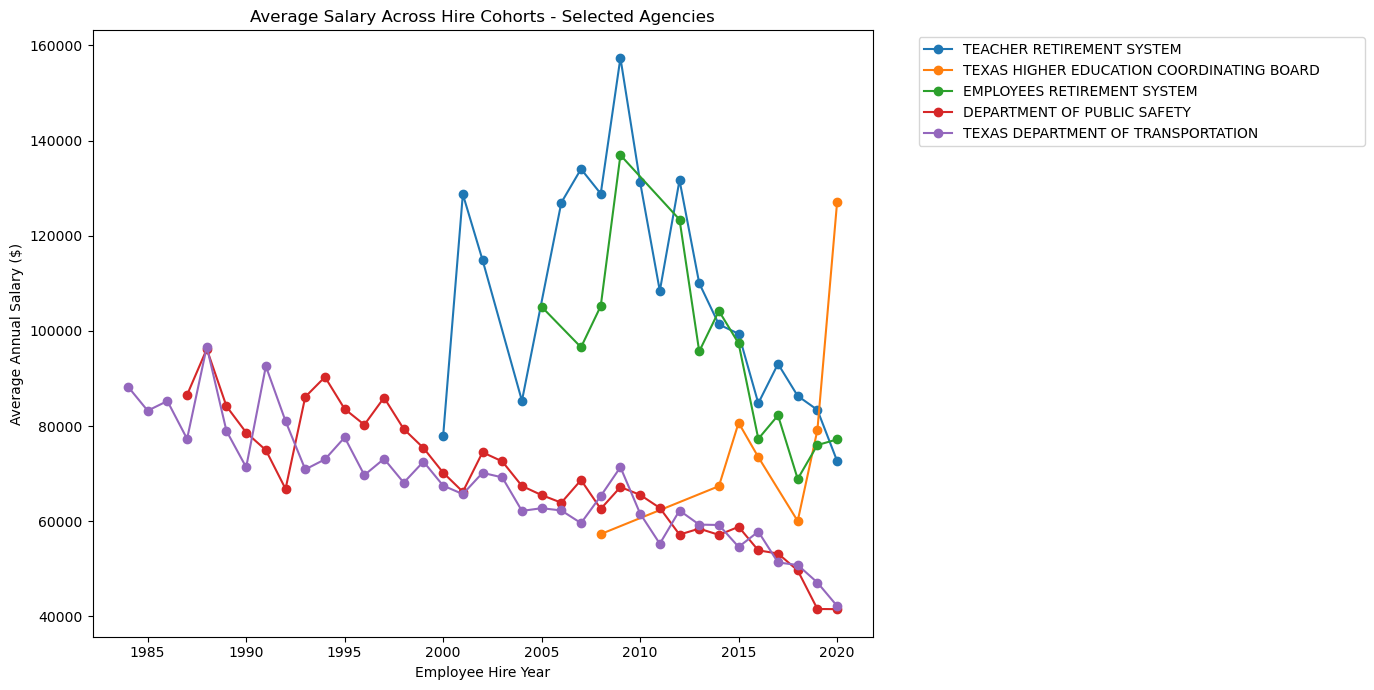

In [130]:
top_agencies = agency_salary_change.head(5)["AGENCY NAME"]

plot_data = agency_year_analysis[
    agency_year_analysis["AGENCY NAME"].isin(top_agencies)
]

plt.figure(figsize=(14, 7))

for agency in top_agencies:
    temp = plot_data[
        plot_data["AGENCY NAME"] == agency
    ].sort_values("EMPLOY YEAR")
    
    plt.plot(
        temp["EMPLOY YEAR"],
        temp["Average_Salary"],
        marker="o",
        label=agency
    )

plt.title("Average Salary Across Hire Cohorts - Selected Agencies")
plt.xlabel("Employee Hire Year")
plt.ylabel("Average Annual Salary ($)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

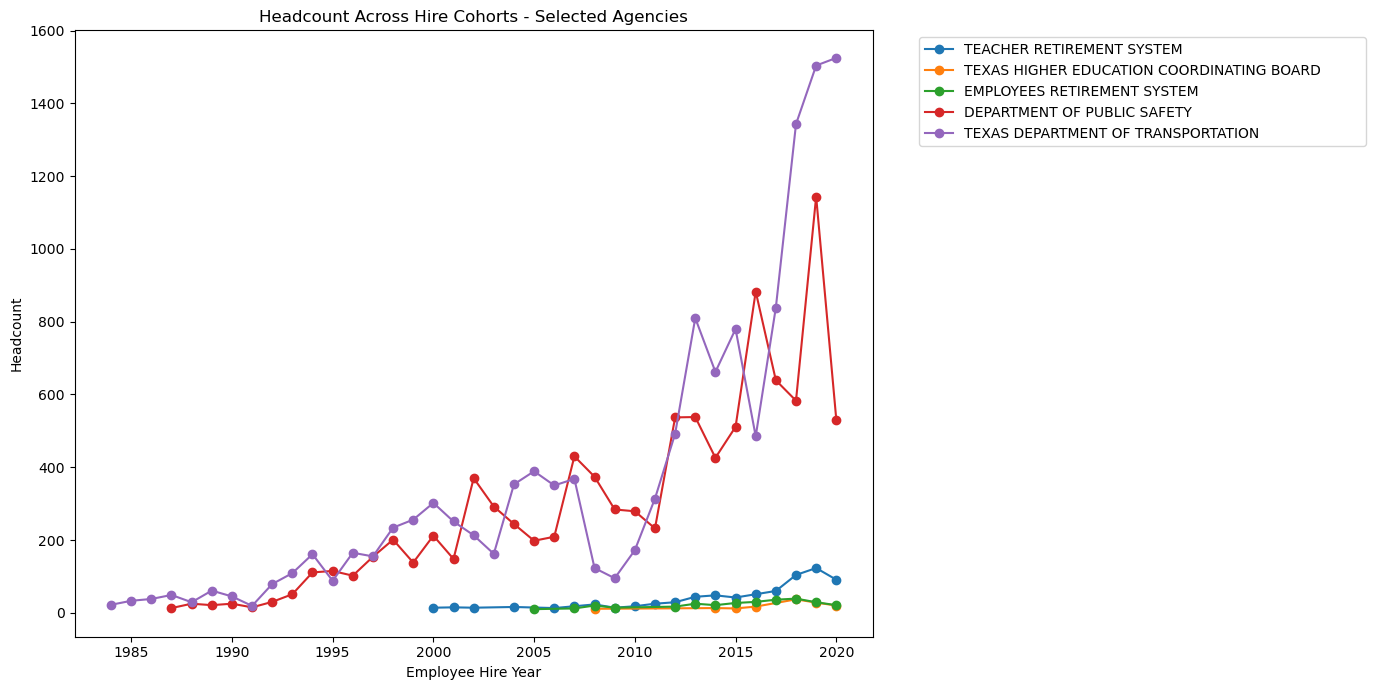

In [131]:
plt.figure(figsize=(14, 7))

for agency in top_agencies:
    temp = plot_data[
        plot_data["AGENCY NAME"] == agency
    ].sort_values("EMPLOY YEAR")
    
    plt.plot(
        temp["EMPLOY YEAR"],
        temp["Headcount"],
        marker="o",
        label=agency
    )

plt.title("Headcount Across Hire Cohorts - Selected Agencies")
plt.xlabel("Employee Hire Year")
plt.ylabel("Headcount")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Changes in Salaries, Roles, Departments and Headcount Over Time

* **Department Salary Changes:** Significant salary variation was observed across departments. Teacher Retirement System had the largest salary range of about **$84,727** across analyzed hiring cohorts.
* **Role Salary Changes:** Roles such as **Elected Officials Staff, Legislative Professional, and District Judge Active** showed notable salary variation across cohorts.
* **Department Headcount:** Major workforce growth was observed in departments such as **HHSC (+13,180)**, **TDCJ (+5,540)**, and **DFPS (+1,761)**.
* **Role Headcount:** **Correc Officer IV (+2,615)**, **Correc Offcr III (+2,358)**, and **Texas Works Advisor II (+786)** showed large changes in headcount.
* **Overall Finding:** Salary levels and workforce size varied considerably across departments and roles over the analyzed hiring years.
* **Data Limitation:** The dataset contains current annual salaries with employment dates, so these results show **salary differences across hiring cohorts**, not historical year-by-year salary increases.



## Key Findings
* **8,595 salary outliers** were identified among 147,119 full-time employees.
* The largest manager-employee wage gap was approximately **$133,790 at CPRIT**.
* Several departments and roles showed substantial changes in **salary levels and headcount across hiring cohorts**.
* **Linear Regression** achieved the best test performance with **MAE = $3,325.55, RMSE = $6,175.38, and R² = 0.9403**.
* Prediction errors increased for higher salary ranges, particularly **above $100,000**.
* Data-quality issues, target leakage, anomalous dates, and employee-level duplication risks were explicitly investigated and addressed.


## Challenges Faced

* **Data Quality Issues:** 8 future employment dates (2068–2075) were identified. They were retained in the dataset but excluded from time-based analysis to avoid misleading results.
* **Repeated Employee Records:** Employees could have multiple records due to different jobs, agencies, or salary records. `STATE NUMBER` was used to group records and investigate repeated employees instead of deleting them automatically.
* **Target Leakage:** `MONTHLY`, `HRLY RATE`, and salary-derived variables were strongly related to `ANNUAL`. These features were removed to prevent artificially inflated model performance.
* **High-Cardinality Features:** Names, employee identifiers, agency codes, and class codes could create excessive unique features. They were excluded from the predictive model to reduce complexity and overfitting risk.
* **Categorical Features:** Variables such as agency, job title, gender, and status required conversion into numerical form. **One-Hot Encoding** with `handle_unknown='ignore'` was used to handle categorical values safely.
* **Train-Test Leakage:** The same employee could have multiple records. **GroupShuffleSplit using `STATE NUMBER`** was used so records from the same employee were not split between training and testing data.
* **Manager Identification:** No official manager indicator was available. A **job-title keyword approach** using terms such as manager, director, supervisor, and chief was used as an approximate classification method.
* **Salary Outliers:** Extreme salaries could represent legitimate senior or specialized positions. The **IQR method** was used to identify outliers, but they were investigated rather than automatically removed.
* **Model Performance:** Different models produced different results. **MAE, RMSE, and R²** were compared to objectively evaluate and select the final model.
* **Large Prediction Errors:** Higher-salary and unusual specialized positions produced larger residuals. **Residual and salary-band analysis** was performed to identify where the model struggled.



## Limitations
* The dataset contains **current annual salaries**, not historical salary records for each year.
* Eight future employment dates indicate possible **data-quality issues**.
* No separate **total compensation** field was available.
* Manager identification was based on **job-title keywords**, not official organizational hierarchy.
* Some salary outliers may represent legitimate senior or specialized positions.
* Model errors were higher for **salaries above $100,000**.
* One-hot encoding increased the feature space from **10 to 1,505 features**.
* The analysis is observational and does not establish **cause-and-effect relationships**.


## Conclusion
* Conducted data cleaning, exploratory analysis, outlier analysis, salary-gap analysis, and time-based workforce analysis.
* Identified **8,595 salary outliers** among 147,119 full-time employees, with most being high-salary observations.
* Found substantial salary differences between manager and employee groups across several agencies.
* Observed significant variation in salary levels and headcount across departments and job roles.
* **Linear Regression** performed best among the tested models:

  * MAE: **$3,325.55**
  * RMSE: **$6,175.38**
  * R²: **0.9403**
* The model performed better for lower and middle salary ranges, while higher salaries produced larger errors.
* Overall, the project demonstrates how data analysis and machine learning can support **payroll analysis and salary prediction** for Texas state government data.
